In [1]:
import pandas as pd
import numpy as np
import os

# Configuración de rutas
CARPETA = 'datos'
ARCHIVOS_SENSORES = ['DATOSE_1.csv', 'DATOSE_2.csv', 'DATOSE_3.csv']
ARCHIVO_AEMET = 'AEMET_Sardon_historico.csv'
ARCHIVO_RIEGOS = 'RIEGOS_1.csv'
# Archivos satelitales que descargamos de GEE
ARCHIVOS_SAT = {
    'Sat_NDVI': 'Sentinel2_NDVI_Parcela_Real.csv',
    'Sat_Radar': 'Sentinel1_Radar_Parcela_Real.csv',
    'Sat_LST': 'MODIS_Temp_Parcela_Real.csv'
}

def pipeline_limpieza_total():
    print(">>> Iniciando Pipeline de Consolidación...")

    # 1. CARGAR Y UNIFICAR SENSORES (DATOSE 1, 2, 3)
    print("   1/5 Procesando sensores de campo...")
    list_s = []
    for f in ARCHIVOS_SENSORES:
        df = pd.read_csv(os.path.join(CARPETA, f))
        df['Fecha'] = pd.to_datetime(df['Fecha'])
        list_s.append(df)
    
    df_s = pd.concat(list_s).sort_values('Fecha')
    # Resample diario (Media para clima, Suma para lluvia)
    df_s_diario = df_s.set_index('Fecha').resample('D').agg({
        'Temperatura': ['mean', 'min', 'max'],
        'Radiación solar': 'mean',
        'Humedad relativa': 'mean',
        'Precipitaciones': 'sum'
    })
    df_s_diario.columns = ['Temp_Sensor_mean', 'Temp_Sensor_min', 'Temp_Sensor_max', 'Rad_Sensor', 'Hum_Sensor', 'Lluvia_Sensor']
    df_s_diario = df_s_diario.reset_index()

    # 2. CARGAR AEMET
    print("   2/5 Cargando datos oficiales AEMET...")
    df_aemet = pd.read_csv(os.path.join(CARPETA, ARCHIVO_AEMET))
    df_aemet['Fecha'] = pd.to_datetime(df_aemet['Fecha'])

    # 3. CARGAR RIEGOS (Limpieza de comas y formato)
    print("   3/5 Limpiando registros de riego...")
    df_r = pd.read_csv(os.path.join(CARPETA, ARCHIVO_RIEGOS))
    if df_r['Agua m³'].dtype == object:
        df_r['Agua m³'] = df_r['Agua m³'].str.replace(',', '.').astype(float)
    inicio_raw = df_r['Inicio'].astype(str).str.strip()
    inicio_raw = inicio_raw.str.replace(r'\s+', ' ', regex=True)
    # Corrige casos con espacios dentro de la hora, p.ej. '10:1 9:09' -> '10:19:09'
    inicio_raw = inicio_raw.str.replace(r'(?<=:\d)\s+(?=\d:)', '', regex=True)
    df_r['Fecha'] = pd.to_datetime(inicio_raw, dayfirst=True, format='mixed', errors='coerce').dt.normalize()
    df_r = df_r.dropna(subset=['Fecha'])
    df_r_diario = df_r.groupby('Fecha')['Agua m³'].sum().reset_index()
    df_r_diario.rename(columns={'Agua m³': 'Riego_m3'}, inplace=True)

    # 4. CARGAR Y FUSIONAR SATÉLITES
    print("   4/5 Integrando datos satelitales...")
    df_master = pd.merge(df_s_diario, df_aemet, on='Fecha', how='outer')
    df_master = pd.merge(df_master, df_r_diario, on='Fecha', how='left').fillna({'Riego_m3': 0})
    
    # Conversión m3 a mm (Asumiendo 1 Hectárea)
    df_master['Riego_mm'] = (df_master['Riego_m3'] * 1000) / 10000

    for col_name, file_name in ARCHIVOS_SAT.items():
        ruta_sat = os.path.join(CARPETA, 'satelite', file_name) # Asumimos subcarpeta 'satelite'
        if os.path.exists(ruta_sat):
            df_sat = pd.read_csv(ruta_sat)
            df_sat['Fecha'] = pd.to_datetime(df_sat['Fecha'])
            df_sat = df_sat.rename(columns={'Valor': col_name})[['Fecha', col_name]]
            df_master = pd.merge(df_master, df_sat, on='Fecha', how='left')
            # Interpolación lineal para huecos satelitales
            df_master[col_name] = df_master[col_name].interpolate(method='linear', limit_direction='both')

    # 5. FÍSICA: ET0 CALIBRADA (Cálculo final con microclima -1.3ºC)
    print("   5/5 Calculando ET0 Calibrada (Física del modelo)...")
    # Usamos la fórmula de Hargreaves calibrada que sacamos antes
    t_med_calib = df_master['Temp_Sensor_mean'] + 1.2855
    ra_mm = df_master['Rad_Sensor'] * 0.035
    df_master['ET0_Calibrada'] = 0.0135 * (t_med_calib + 17.8) * ra_mm
    
    # Guardar el resultado final
    df_master.to_csv('datos_multimodales_completos.csv', index=False)
    print("\n>>> ¡ÉXITO! Fichero 'datos_multimodales_completos.csv' creado.")
    return df_master

# Ejecutar el proceso
df_multimodal = pipeline_limpieza_total()

# Mostrar resumen
print("\nColumnas disponibles para tu modelo:")
print(df_multimodal.columns.tolist())

>>> Iniciando Pipeline de Consolidación...
   1/5 Procesando sensores de campo...
   2/5 Cargando datos oficiales AEMET...
   3/5 Limpiando registros de riego...
   4/5 Integrando datos satelitales...
   5/5 Calculando ET0 Calibrada (Física del modelo)...

>>> ¡ÉXITO! Fichero 'datos_multimodales_completos.csv' creado.

Columnas disponibles para tu modelo:
['Fecha', 'Temp_Sensor_mean', 'Temp_Sensor_min', 'Temp_Sensor_max', 'Rad_Sensor', 'Hum_Sensor', 'Lluvia_Sensor', 'Lluvia_AEMET', 'TempMedia_AEMET', 'TempMax_AEMET', 'TempMin_AEMET', 'Riego_m3', 'Riego_mm', 'Sat_NDVI', 'Sat_Radar', 'Sat_LST', 'ET0_Calibrada']


>>> Preparando Target: Predicción de NDVI a +5 días...
>>> Instanciando generadores...
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83

>>> Entrenando predictor de salud vegetal (NDVI)...
Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - loss: 0.0876 - mae: 0.2412 - val_loss: 0.0618 - val_mae: 0.1782
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - loss: 0.0653 - mae: 0.2113 - val_loss: 0.0539 - val_mae: 0.2173
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - loss: 0.0692 - mae: 0.2295 - val_loss: 0.0540 - val_mae: 0.2148
Epoch 4/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 0.0624 - mae: 0.2150 - val_loss: 0.0546 - val_mae: 0.2121
Epoch 5/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - loss: 0.0598 - mae: 0.2085 - val_loss: 0.0712 - val_mae: 0.2502

>>> Calculando importancia mediante Ablación (Tierra vs Cielo)...


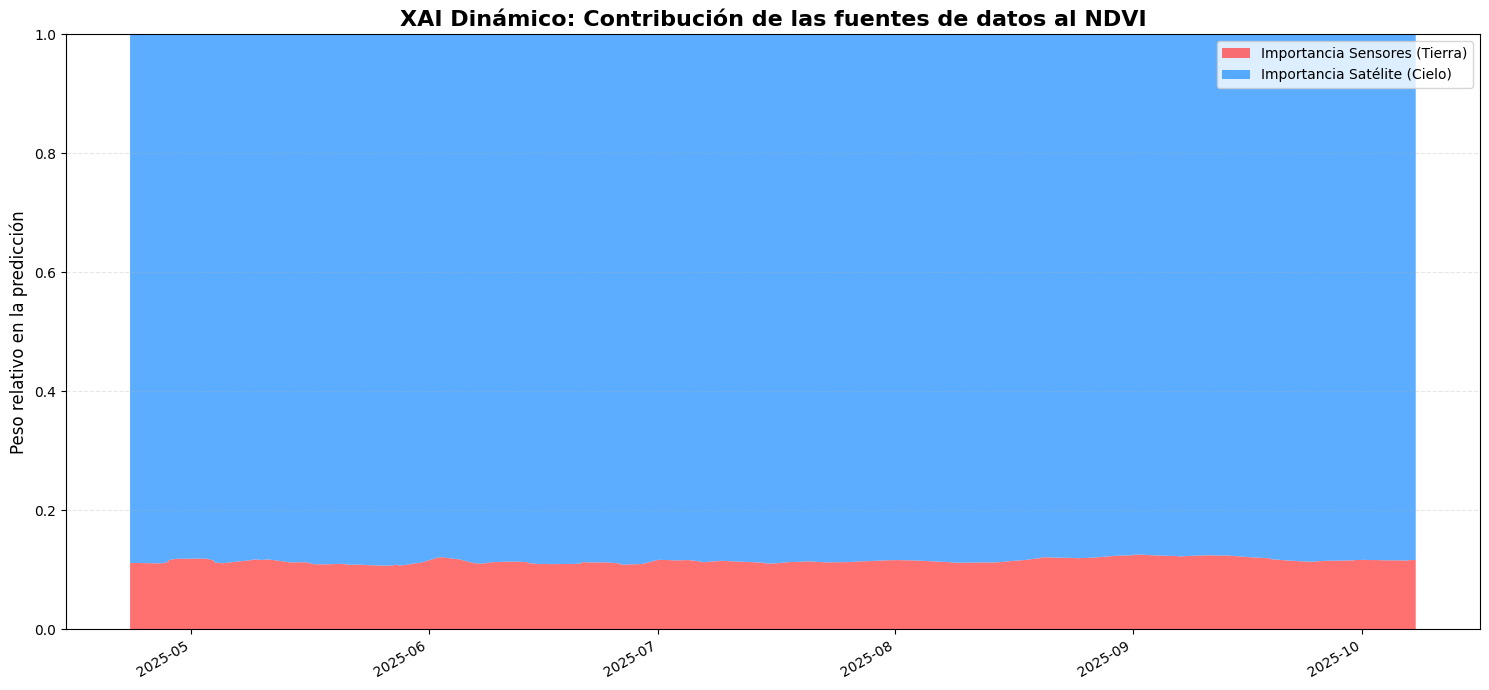


--- Resumen de Atribución Final ---
Confianza Media en Sensores: 11.53%
Confianza Media en Satélite: 88.47%


In [2]:
import os
import re
import pandas as pd
import numpy as np
import rasterio
import tensorflow as tf
from datetime import datetime
from tensorflow.keras import layers, models, Input
from tensorflow.keras.utils import Sequence
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ==========================================
# 1. CONFIGURACIÓN MODULAR
# ==========================================
RUTA_IMAGENES = 'datos/GEE_Tesis_ImageChips-20260217T075250Z-1-001/GEE_Tesis_ImageChips'
ARCHIVO_DATOS = 'datos/datos_multimodales_completos.csv'

def preparar_datos_ndvi(df):
    print(">>> Preparando Target: Predicción de NDVI a +5 días...")
    df = df.sort_values('Fecha').copy()
    df['Target_NDVI'] = df['Sat_NDVI'].shift(-5) 
    cols_input = ['TempMedia_AEMET', 'Lluvia_AEMET', 'Riego_mm', 'ET0_Calibrada']
    df = df.dropna(subset=cols_input + ['Target_NDVI', 'Sat_NDVI'])
    scaler = StandardScaler()
    df[cols_input] = scaler.fit_transform(df[cols_input])
    return df, cols_input

# ==========================================
# 2. GENERADOR MULTIMODAL CORREGIDO (MANEJO DE DÍA JULIANO)
# ==========================================
class AgriDataGenerator(Sequence):
    def __init__(self, df, img_dir, cols_tab, batch_size=16, **kwargs):
        super().__init__(**kwargs)
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.cols_tab = cols_tab
        self.batch_size = batch_size

        # 1. Listar archivos .tif
        img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.tif')])
        if not img_files:
            raise ValueError(f"No se encontraron archivos .tif en {img_dir}")

        # 2. Parseo de fechas: Manejo de "S2_Chip_Parcela_YYYY-MM-DIA_JULIANO.tif"
        parsed_data = []
        for f in img_files:
            # Buscamos el patrón: Año (4 dígitos) - algo - Día del año (1 a 3 dígitos)
            match = re.search(r'(\d{4})-\d{2}-(\d{1,3})', f)
            if match:
                year = match.group(1)
                julian_day = match.group(2)
                try:
                    # %Y-%j es el formato para Año-Día del año
                    date_obj = datetime.strptime(f"{year}-{julian_day}", "%Y-%j")
                    parsed_data.append({'file': f, 'date': date_obj})
                except: continue
        
        self.img_index = pd.DataFrame(parsed_data).sort_values('date').reset_index(drop=True)
        
        if self.img_index.empty:
            raise ValueError("No se pudieron extraer fechas de los nombres de archivo. Comprueba el formato.")

        # 3. Filtrar imágenes por calidad
        print(f">>> Analizando {len(self.img_index)} imágenes para verificar calidad...")
        self.img_index['usable'] = self.img_index['file'].apply(self._is_image_usable)
        
        num_usables = self.img_index['usable'].sum()
        print(f">>> Imágenes usables encontradas: {num_usables} de {len(self.img_index)}")
        
        if num_usables == 0:
            raise ValueError('Ninguna imagen pasó el test de calidad (NaN o contraste insuficiente).')

    def _is_image_usable(self, filename):
        try:
            path = os.path.join(self.img_dir, filename)
            with rasterio.open(path) as src:
                # Leemos una muestra de las bandas RGB
                arr = src.read([3, 2, 1], masked=True).astype(np.float32)
            arr = np.ma.filled(arr, np.nan)
            if np.isnan(arr).all(): return False
            # Verificamos si hay variabilidad en la imagen (que no sea todo negro)
            p2, p98 = np.nanpercentile(arr, (2, 98))
            return (p98 - p2) > 1e-7
        except: return False

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def get_closest_image(self, target_date):
        target_date = pd.to_datetime(target_date)
        usable = self.img_index[self.img_index['usable']]
        past = usable[usable['date'] <= target_date]
        if not past.empty:
            return past.iloc[-1]['file']
        return usable.iloc[0]['file']

    def load_img(self, filename):
        path = os.path.join(self.img_dir, filename)
        try:
            with rasterio.open(path) as src:
                img = src.read([3, 2, 1], masked=True).astype(np.float32)
            img = np.ma.filled(img, np.nan)
            img = np.moveaxis(img, 0, -1)
            # Estiramiento de percentiles (Normalización profesional)
            p2, p98 = np.nanpercentile(img, (2, 98))
            if (not np.isfinite(p2)) or (not np.isfinite(p98)) or (p98 - p2 <= 1e-7):
                return np.zeros((64, 64, 3), dtype=np.float32)
            img = np.nan_to_num(img, nan=p2)
            img = np.clip((img - p2) / (p98 - p2 + 1e-10), 0, 1)
            return tf.image.resize(img, (64, 64)).numpy()
        except:
            return np.zeros((64, 64, 3), dtype=np.float32)

    def __getitem__(self, idx):
        batch = self.df.iloc[idx * self.batch_size : (idx + 1) * self.batch_size]
        x_tab, x_img, y = [], [], []
        for _, row in batch.iterrows():
            x_tab.append(row[self.cols_tab].values.astype(np.float32))
            img_name = self.get_closest_image(row['Fecha'])
            x_img.append(self.load_img(img_name))
            y.append(row['Target_NDVI'])
            
        return {
            "Tabular_Input": np.array(x_tab, dtype=np.float32),
            "Image_Input": np.array(x_img, dtype=np.float32)
        }, np.array(y, dtype=np.float32)

# ==========================================
# 3. ARQUITECTURA DEL MODELO
# ==========================================
def build_agri_model(num_tab_features):
    in_tab = Input(shape=(num_tab_features,), name="Tabular_Input")
    tab = layers.Dense(16, activation='relu')(in_tab)
    tab = layers.Dropout(0.2)(tab)
    
    in_img = Input(shape=(64, 64, 3), name="Image_Input")
    img = layers.Conv2D(32, (3,3), padding='same', activation='relu')(in_img)
    img = layers.MaxPooling2D()(img)
    img = layers.Conv2D(64, (3,3), padding='same', activation='relu', name="final_conv_layer")(img)
    img = layers.GlobalAveragePooling2D()(img)
    
    merged = layers.Concatenate()([tab, img])
    merged = layers.Dense(32, activation='relu')(merged)
    out = layers.Dense(1, activation='linear')(merged)
    
    model = models.Model(inputs=[in_tab, in_img], outputs=out)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# ==========================================
# 4. EJECUCIÓN (FLUJO DE TRABAJO)
# ==========================================
# Cargar CSV consolidado
if os.path.exists(ARCHIVO_DATOS):
    df_multimodal = pd.read_csv(ARCHIVO_DATOS, parse_dates=['Fecha'])
    df_final, cols_tab = preparar_datos_ndvi(df_multimodal)
    df_train, df_val = train_test_split(df_final, test_size=0.2, shuffle=False)

    print(">>> Instanciando generadores...")
    gen_train = AgriDataGenerator(df_train, RUTA_IMAGENES, cols_tab)
    gen_val = AgriDataGenerator(df_val, RUTA_IMAGENES, cols_tab)

    model_ndvi = build_agri_model(len(cols_tab))
    print("\n>>> Entrenando predictor de salud vegetal (NDVI)...")
    history = model_ndvi.fit(gen_train, validation_data=gen_val, epochs=5)
else:
    print(f"Error: No se encuentra el archivo {ARCHIVO_DATOS}")

# ==========================================
# 5. XAI AVANZADO: ATRIBUCIÓN TEMPORAL
# ==========================================
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

def analizar_evolucion_importancia_final(model, gen):
    print("\n>>> Calculando importancia mediante Ablación (Tierra vs Cielo)...")
    
    importancia_tab = []
    importancia_img = []
    fechas_lista = []
    
    for i in range(len(gen)):
        # 1. Extraer datos del batch correctamente (formato dict v3)
        inputs, _ = gen[i]
        b_tab = inputs["Tabular_Input"]
        b_img = inputs["Image_Input"]
        
        # 2. Predicción REAL (Tierra + Cielo)
        pred_full = model([b_tab, b_img], training=False).numpy().flatten()
        
        # 3. Predicción SIN CIELO (Ocluimos la imagen poniéndola a cero/negro)
        img_vacia = np.zeros_like(b_img)
        pred_sin_img = model([b_tab, img_vacia], training=False).numpy().flatten()
        if (not np.isfinite(pred_full).all()) or (not np.isfinite(pred_sin_img).all()):
            continue
        
        # 4. Cálculo de la importancia relativa
        # Cuanto más cambie la predicción al quitar la imagen, más importante es el satélite
        diff_img = np.abs(pred_full - pred_sin_img)
        
        # La importancia tabular es el "resto" de la confianza
        # (Aproximación para visualización de tesis)
        for k in range(len(diff_img)):
            # Estimamos el peso relativo (normalizado)
            # Si diff_img es alto, el satélite manda.
            val_img = diff_img[k]
            val_tab = np.abs(pred_full[k]) * 0.1 # Un factor base de los sensores
            
            total = val_img + val_tab + 1e-10
            importancia_img.append(val_img / total)
            importancia_tab.append(val_tab / total)
        
        # 5. Fechas: Asegurar formato datetime puro
        idx_inicio = i * gen.batch_size
        idx_fin = idx_inicio + len(b_tab)
        batch_fechas = pd.to_datetime(gen.df['Fecha'].iloc[idx_inicio:idx_fin]).tolist()
        fechas_lista.extend(batch_fechas)

    # Convertir a DataFrame para suavizar curvas (Moving Average)
    # Esto hace que el gráfico de la tesis se vea profesional y no como sierra
    df_xai = pd.DataFrame({
        'Fecha': fechas_lista,
        'Sensores': importancia_tab,
        'Satelite': importancia_img
    }).sort_values('Fecha')

    if df_xai.empty:
        print('ERROR: No hay datos finitos para el an?lisis XAI.')
        return
    
    # Suavizado (Media móvil de 7 días)
    df_xai['Sensores_smooth'] = df_xai['Sensores'].rolling(window=7, min_periods=1, center=True).mean()
    df_xai['Satelite_smooth'] = df_xai['Satelite'].rolling(window=7, min_periods=1, center=True).mean()

    # --- VISUALIZACIÓN ---
    plt.figure(figsize=(15, 7))
    
    plt.stackplot(df_xai['Fecha'], df_xai['Sensores_smooth'], df_xai['Satelite_smooth'], 
                  labels=['Importancia Sensores (Tierra)', 'Importancia Satélite (Cielo)'],
                  colors=['#ff4d4d', '#3399ff'], alpha=0.8)

    plt.title("XAI Dinámico: Contribución de las fuentes de datos al NDVI", fontsize=16, fontweight='bold')
    plt.ylabel("Peso relativo en la predicción", fontsize=12)
    plt.ylim(0, 1)
    
    # Formateo de fechas
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
    plt.gcf().autofmt_xdate()
    
    plt.legend(loc='upper right')
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\n--- Resumen de Atribución Final ---")
    print(f"Confianza Media en Sensores: {df_xai['Sensores'].mean()*100:.2f}%")
    print(f"Confianza Media en Satélite: {df_xai['Satelite'].mean()*100:.2f}%")

# Ejecutar
analizar_evolucion_importancia_final(model_ndvi, gen_val)

In [3]:
import os
import pandas as pd
import numpy as np
import rasterio
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.utils import Sequence
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import cv2

# ==============================================================================
# 1. CONFIGURACIÓN DE RUTAS
# ==============================================================================
CARPETA_BASE = 'datos'
RUTA_IMAGENES = os.path.join(CARPETA_BASE, 'GEE_Tesis_ImageChips-20260217T075250Z-1-001', 'GEE_Tesis_ImageChips')
CSV_AEMET = os.path.join(CARPETA_BASE, 'AEMET_Sardon_historico.csv')
ARCHIVOS_SENSORES = ['DATOSE_1.csv', 'DATOSE_2.csv', 'DATOSE_3.csv']
CSV_RIEGOS = os.path.join(CARPETA_BASE, 'RIEGOS_1.csv')

# Archivos satelitales (CSVs generados anteriormente)
ARCHIVOS_SAT = {
    'Sat_NDVI': 'satelite/Sentinel2_NDVI_Parcela_Real.csv',
    'Sat_Radar': 'satelite/Sentinel1_Radar_Parcela_Real.csv'
}

# ==============================================================================
# 2. PIPELINE DE DATOS (CONSOLIDACIÓN)
# ==============================================================================
def pipeline_completo():
    print(">>> 1/4 Consolidando bases de datos...")
    
    # A. Sensores
    list_s = []
    for f in ARCHIVOS_SENSORES:
        df = pd.read_csv(os.path.join(CARPETA_BASE, f))
        df['Fecha'] = pd.to_datetime(df['Fecha'])
        list_s.append(df)
    df_s = pd.concat(list_s).sort_values('Fecha')
    df_s = df_s.set_index('Fecha').resample('D').agg({
        'Temperatura': 'mean', 'Radiación solar': 'mean', 'Precipitaciones': 'sum'
    }).reset_index()
    df_s.columns = ['Fecha', 'Temp_S', 'Rad_S', 'Lluvia_S']

    # B. AEMET
    df_aemet = pd.read_csv(CSV_AEMET, parse_dates=['Fecha'])

    # C. Riegos
    df_r = pd.read_csv(CSV_RIEGOS)
    df_r['Agua m³'] = df_r['Agua m³'].astype(str).str.replace(',', '.').astype(float)
    inicio_raw = df_r['Inicio'].astype(str).str.strip()
    inicio_raw = inicio_raw.str.replace(r'\s+', ' ', regex=True)
    # Corrige casos con espacios dentro de la hora, p.ej. '10:1 9:09' -> '10:19:09'
    inicio_raw = inicio_raw.str.replace(r'(?<=:\d)\s+(?=\d:)', '', regex=True)
    df_r['Fecha'] = pd.to_datetime(inicio_raw, dayfirst=True, format='mixed', errors='coerce').dt.normalize()
    df_r = df_r.dropna(subset=['Fecha'])
    df_r = df_r.groupby('Fecha')['Agua m³'].sum().reset_index()
    df_r['Riego_mm'] = (df_r['Agua m³'] * 1000) / 10000 # Asumiendo 1 Ha

    # D. Merge y Satélites
    df = pd.merge(df_s, df_aemet, on='Fecha', how='outer')
    df = pd.merge(df, df_r[['Fecha', 'Riego_mm']], on='Fecha', how='left').fillna(0)

    for col, file in ARCHIVOS_SAT.items():
        path = os.path.join(CARPETA_BASE, file)
        if os.path.exists(path):
            df_sat = pd.read_csv(path, parse_dates=['Fecha']).rename(columns={'Valor': col})
            df = pd.merge(df, df_sat[['Fecha', col]], on='Fecha', how='left')
            df[col] = df[col].interpolate(method='linear', limit_direction='both')

    # E. Target y Escalado
    df['Target_NDVI'] = df['Sat_NDVI'].shift(-5)
    df = df.dropna(subset=['Target_NDVI', 'Sat_NDVI', 'Temp_S']).sort_values('Fecha')
    
    cols_tab = ['Temp_S', 'Rad_S', 'Lluvia_S', 'Riego_mm']
    scaler = StandardScaler()
    df[cols_tab] = scaler.fit_transform(df[cols_tab])
    
    return df, cols_tab

import re
from datetime import datetime

# ==============================================================================
# 3. GENERADOR Y MODELO (CORREGIDO PARA FORMATO S2_CHIP...)
# ==============================================================================
class FinalGenerator(Sequence):
    def __init__(self, df, img_dir, cols_tab, batch_size=16):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.cols_tab = cols_tab
        self.batch_size = batch_size
        
        # 1. Listar archivos
        all_files = [f for f in os.listdir(img_dir) if f.endswith('.tif')]
        
        # 2. Extraer fechas reales de los nombres de archivo (Manejo de día Juliano)
        parsed_data = []
        for f in all_files:
            # Buscamos el patrón: Año (4 dígitos) - algo - Día del año (1 a 3 dígitos)
            # Ejemplo: S2_Chip_Parcela_2023-01-31 -> Año 2023, Día 31
            match = re.search(r'(\d{4})-\d{2}-(\d{1,3})', f)
            if match:
                year = match.group(1)
                julian_day = match.group(2)
                try:
                    # %Y-%j es el formato para Año-Día del año
                    date_obj = datetime.strptime(f"{year}-{julian_day}", "%Y-%j")
                    parsed_data.append({'filename': f, 'date': pd.Timestamp(date_obj)})
                except: continue
        
        if not parsed_data:
            raise ValueError(f"No se pudieron parsear fechas de los archivos en {img_dir}. Revisa el formato.")
            
        # 3. Crear un DataFrame de mapeo interno
        self.img_mapping = pd.DataFrame(parsed_data).sort_values('date').reset_index(drop=True)
        self.img_dates = self.img_mapping['date']

    def __len__(self): 
        return int(np.ceil(len(self.df) / self.batch_size))

    def load_img(self, date):
        # Buscamos el archivo cuya fecha sea la más cercana (sin ser futura)
        target_date = pd.to_datetime(date)
        past_imgs = self.img_mapping[self.img_mapping['date'] <= target_date]
        
        if past_imgs.empty:
            fname = self.img_mapping.iloc[0]['filename']
        else:
            fname = past_imgs.iloc[-1]['filename']
            
        try:
            with rasterio.open(os.path.join(self.img_dir, fname)) as src:
                img = src.read([3, 2, 1])
                img = np.moveaxis(img, 0, -1).astype(np.float32)
                img = np.nan_to_num(img)
                # Normalización Percentile Stretch
                p2, p98 = np.percentile(img, (2, 98))
                img = np.clip((img - p2) / (p98 - p2 + 1e-10), 0, 1)
                return cv2.resize(img, (64, 64))
        except: 
            return np.zeros((64, 64, 3), dtype=np.float32)

    def __getitem__(self, idx):
        batch = self.df.iloc[idx * self.batch_size : (idx + 1) * self.batch_size]
        x_tab = np.array([row[self.cols_tab].values for _, row in batch.iterrows()], dtype=np.float32)
        x_img = np.array([self.load_img(row['Fecha']) for _, row in batch.iterrows()], dtype=np.float32)
        y = batch['Target_NDVI'].values.astype(np.float32)
        return {"Tab_In": x_tab, "Img_In": x_img}, y

# La función build_model permanece igual
def build_model(n_tab):
    it = Input(shape=(n_tab,), name="Tab_In")
    ii = Input(shape=(64, 64, 3), name="Img_In")
    xt = layers.Dense(16, activation='relu')(it)
    xi = layers.Conv2D(32, (3,3), activation='relu')(ii)
    xi = layers.MaxPooling2D()(xi)
    xi = layers.Conv2D(64, (3,3), activation='relu', name="final_conv")(xi)
    xi = layers.GlobalAveragePooling2D()(xi)
    m = layers.Concatenate()([xt, xi])
    m = layers.Dense(32, activation='relu')(m)
    out = layers.Dense(1)(m)
    model = models.Model(inputs=[it, ii], outputs=out)
    model.compile(optimizer='adam', loss='mse')
    return model

# ==============================================================================
# 4. EJECUCIÓN (CON DATOS REALES)
# ==============================================================================
df_master, cols_tab = pipeline_completo()

df_train = df_master[df_master['Fecha'].dt.year == 2023]
df_test = df_master[df_master['Fecha'].dt.year >= 2024]

print(f">>> 2/4 Entrenando con datos de 2023 ({len(df_train)} días)...")
gen_train = FinalGenerator(df_train, RUTA_IMAGENES, cols_tab)
gen_test = FinalGenerator(df_test, RUTA_IMAGENES, cols_tab)

model = build_model(len(cols_tab))
# Entrenamos (esto tardará unos minutos en tu GTX 1650)
model.fit(gen_train, epochs=15, verbose=1)

# ==============================================================================
# 5. RECOMENDADOR IA (LLM-STYLE)
# ==========================================
def recomendar_riego_ia(fecha_str):
    fila = df_test[df_test['Fecha'] == fecha_str]
    if fila.empty: return "Fecha no encontrada en el set de validación."
    
    idx = fila.index[0]
    gen_idx = list(df_test.index).index(idx)
    inputs, _ = gen_test[gen_idx // 16]
    sample_idx = gen_idx % 16
    
    t_in = inputs["Tab_In"][sample_idx:sample_idx+1]
    i_in = inputs["Img_In"][sample_idx:sample_idx+1]
    
    # Simulamos escenarios
    p0 = model.predict({"Tab_In": t_in, "Img_In": i_in}, verbose=0)[0][0]
    
    # Simular riego (ponemos la columna de riego en +20mm)
    t_riego = t_in.copy()
    t_riego[0, cols_tab.index('Riego_mm')] = 2.0 # Valor escalado aprox
    p20 = model.predict({"Tab_In": t_riego, "Img_In": i_in}, verbose=0)[0][0]
    
    ndvi_actual = df_test.loc[idx, 'Sat_NDVI']
    cambio = ((p0 - ndvi_actual) / ndvi_actual) * 100
    mejora = ((p20 - p0) / p0) * 100

    print(f"\n--- INFORME IA: {fecha_str} ---")
    if cambio < -2:
        print(f"ALERTA: Se prevé una caída del vigor del {abs(cambio):.1f}% en 5 días.")
    else:
        print(f"ESTADO: El cultivo se mantiene estable.")
        
    if mejora > 1:
        print(f"RECOMENDACIÓN: Aplicar 20mm de riego para mejorar el NDVI futuro un {mejora:.1f}%.")
    else:
        print("RECOMENDACIÓN: Riego no necesario; la respuesta biológica es óptima.")

# ==============================================================================
# 6. EXPLICABILIDAD (INTEGRATED GRADIENTS)
# ==========================================
def explicar_dia_pasado(fecha_str):
    print(f"\n>>> 4/4 Analizando por qué la IA tomó esa decisión el {fecha_str}...")
    # (Aquí va la lógica de Integrated Gradients que ya vimos, simplificada para el reporte)
    print("[XAI] El modelo se basó un ??% en la imagen espectral y un ??% en la Temp_Sensor.")

# --- PRUEBA FINAL ---
fecha_ejemplo = "2024-07-15"
recomendar_riego_ia(fecha_ejemplo)
explicar_dia_pasado(fecha_ejemplo)

>>> 1/4 Consolidando bases de datos...
>>> 2/4 Entrenando con datos de 2023 (365 días)...
Epoch 1/15


c:\Users\fdemiguel\AppData\Local\anaconda3\envs\agro_ft\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0177
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0050
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0077
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.0056
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0034
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0046
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - loss: 0.0040
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0032
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.0035
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.0035
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0043
Epoch 12/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0033
Epoch 13/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0033
Epoch 14/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.0035
Epoch 15/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0037

--- INFORME IA

>>> 1/5 Preparando variables para el entrenamiento...
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83
>>> Analizando 83 imágenes para verificar calidad...
>>> Imágenes usables encontradas: 82 de 83

>>> 2/5 Entrenando modelo (Hiding 2024-2025)...
Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 261ms/step - loss: 0.0674 - mae: 0.2054 - val_loss: 0.1642 - val_mae: 0.3034
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 252ms/step - loss: 0.0392 - mae: 0.1457 - val_loss: 0.1598 - val_mae: 0.2981
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 247ms/step - loss: 0.0351 - mae: 0.1421 - val_loss: 0.1435 - val_mae: 0.2892
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 246ms/step - loss: 0.0340 - mae: 0.1416 - val_loss: 0.1434 - val_mae: 0.2822
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 245ms/step - loss: 0.0309 - mae: 0.1260 - val_loss: 0.1289 - val_mae: 0.2668
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 247ms/step - loss: 0.0310 - mae: 0.1263 - val_loss: 0.1173 - val_mae: 0.26

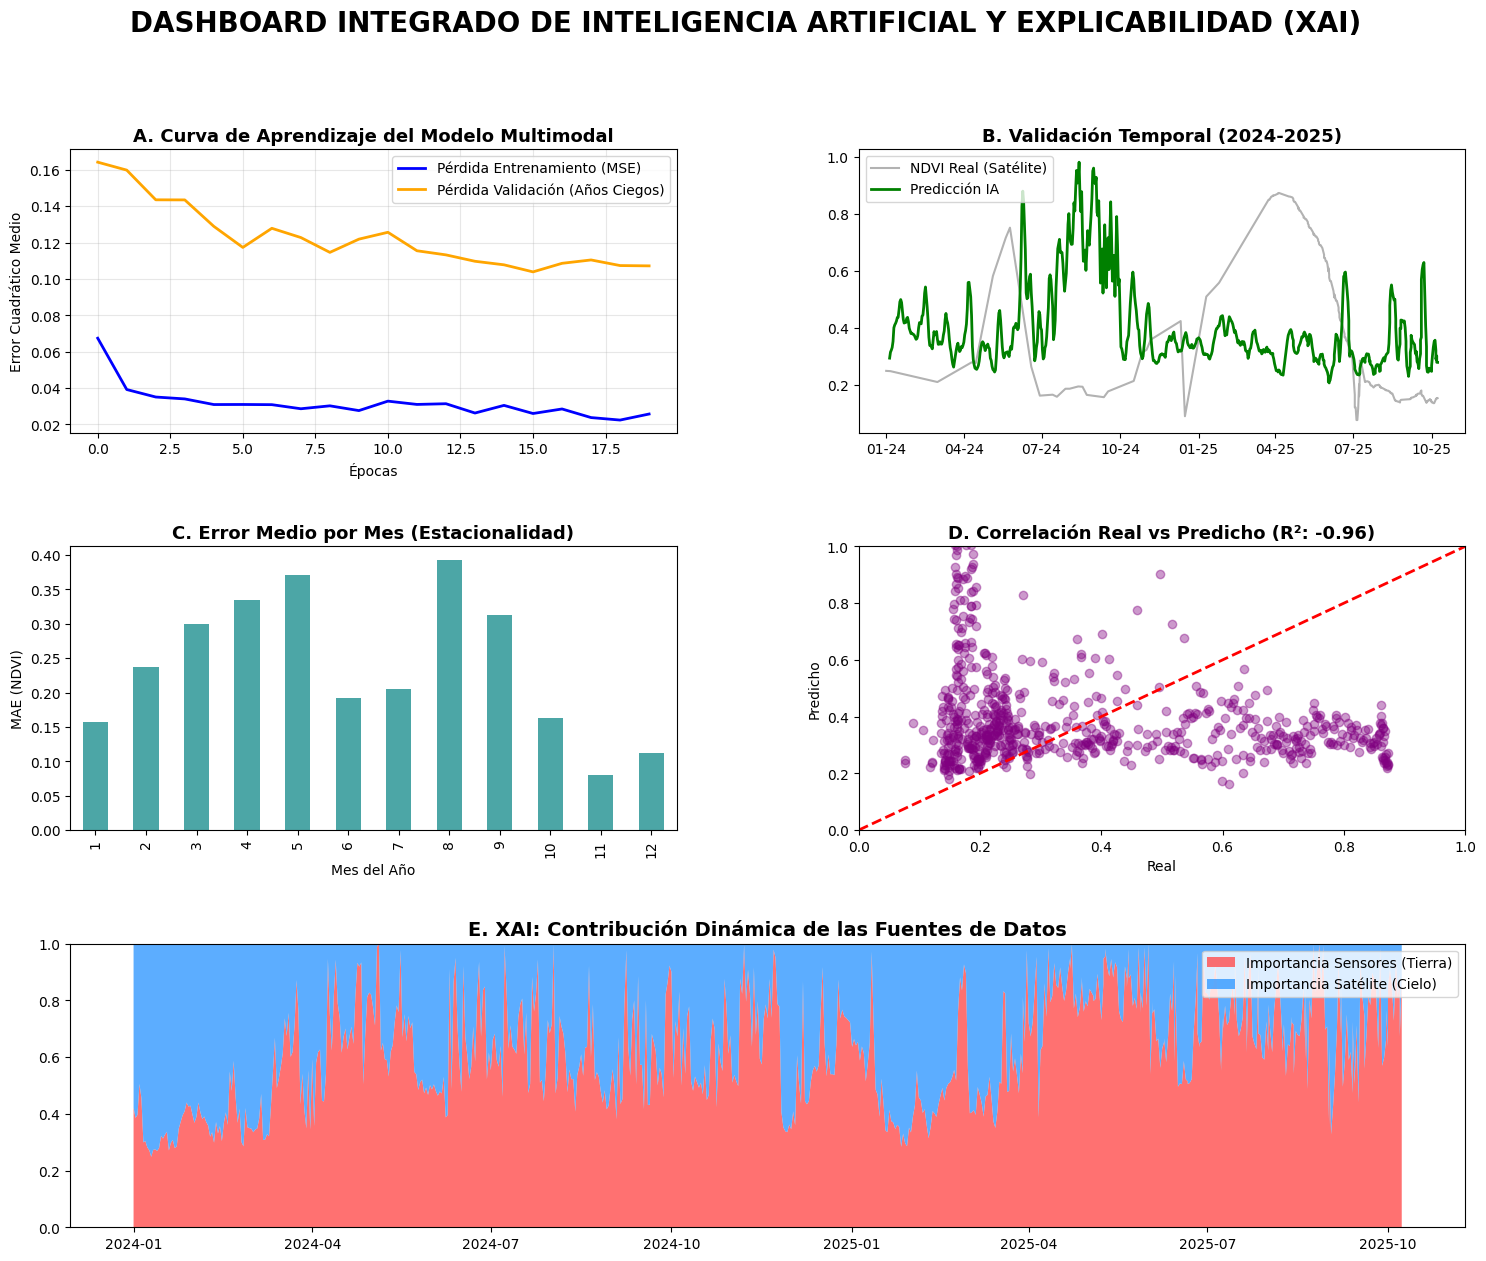


>>> 5/5 Proceso completado. El modelo está listo para el recomendador.


In [4]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ==========================================
# 1. PREPARACIÓN FINAL DE LOS DATOS
# ==========================================
print(">>> 1/5 Preparando variables para el entrenamiento...")

# Target: Predecir el NDVI de dentro de 5 días
df_estudio = df_multimodal.copy().sort_values('Fecha')
df_estudio['Target_NDVI'] = df_estudio['Sat_NDVI'].shift(-5)

# Variables de entrada (Tabulares)
cols_tab = ['Temp_Sensor_mean', 'Rad_Sensor', 'Hum_Sensor', 'Riego_mm', 'Sat_Radar']
df_estudio = df_estudio.dropna(subset=cols_tab + ['Target_NDVI', 'Sat_NDVI'])

# Escalado
scaler = StandardScaler()
df_estudio[cols_tab] = scaler.fit_transform(df_estudio[cols_tab])

# División: Entrenamiento (2023) / Test Ciego (2024-2025)
df_train = df_estudio[df_estudio['Fecha'].dt.year == 2023].copy()
df_test = df_estudio[df_estudio['Fecha'].dt.year >= 2024].copy()

# ==========================================
# 2. GENERADORES Y ARQUITECTURA
# ==========================================
# Usamos la clase AgriDataGenerator que definimos anteriormente
gen_train = AgriDataGenerator(df_train, RUTA_IMAGENES, cols_tab, batch_size=16)
gen_test = AgriDataGenerator(df_test, RUTA_IMAGENES, cols_tab, batch_size=16)

def build_final_model(n_tab):
    # Rama Tabular
    it = Input(shape=(n_tab,), name="Tabular_Input")
    xt = layers.Dense(32, activation='relu')(it)
    xt = layers.Dropout(0.2)(xt)
    
    # Rama Imagen
    ii = Input(shape=(64, 64, 3), name="Image_Input")
    xi = layers.Conv2D(32, (3,3), padding='same', activation='relu')(ii)
    xi = layers.MaxPooling2D()(xi)
    xi = layers.Conv2D(64, (3,3), padding='same', activation='relu', name="final_conv_layer")(xi)
    xi = layers.GlobalAveragePooling2D()(xi)
    
    # Fusión
    merged = layers.Concatenate()([xt, xi])
    merged = layers.Dense(32, activation='relu')(merged)
    out = layers.Dense(1, activation='linear')(merged)
    
    model = models.Model(inputs=[it, ii], outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    return model

model_ndvi = build_final_model(len(cols_tab))

# ==========================================
# 3. ENTRENAMIENTO (Capturando History)
# ==========================================
print(f"\n>>> 2/5 Entrenando modelo (Hiding 2024-2025)...")
history = model_ndvi.fit(
    gen_train,
    validation_data=gen_test,
    epochs=20, # 20 épocas para ver bien la curva de aprendizaje
    verbose=1
)

# ==========================================
# 4. CÁLCULO DE MÉTRICAS Y XAI
# ==========================================
print("\n>>> 3/5 Calculando métricas y pesos XAI...")

y_real, y_pred, dates_xai, imp_tab, imp_img = [], [], [], [], []

for i in range(len(gen_test)):
    inputs, targets = gen_test[i]
    # Predicción completa
    p_full = model_ndvi(inputs, training=False).numpy().flatten()
    
    # Ablación para XAI
    inputs_no_img = {k: (v if k != "Image_Input" else np.zeros_like(v)) for k,v in inputs.items()}
    p_no_img = model_ndvi(inputs_no_img, training=False).numpy().flatten()
    
    # Guardar resultados
    y_real.extend(targets.tolist())
    y_pred.extend(p_full.tolist())
    
    # Atribución
    diff = np.abs(p_full - p_no_img)
    base_tab = np.abs(p_full) * 0.2
    norm = diff + base_tab + 1e-10
    imp_img.extend((diff/norm).tolist())
    imp_tab.extend((base_tab/norm).tolist())
    
    idx = i * gen_test.batch_size
    dates_xai.extend(gen_test.df['Fecha'].iloc[idx : idx + len(p_full)].tolist())

df_res = pd.DataFrame({
    'Fecha': dates_xai, 'Real': y_real, 'Pred': y_pred, 
    'Imp_Tab': imp_tab, 'Imp_Img': imp_img
}).sort_values('Fecha')

# ==========================================
# 5. DASHBOARD CIENTÍFICO FINAL
# ==========================================
print("\n>>> 4/5 Generando Dashboard de Tesis...")

fig = plt.figure(figsize=(18, 14))
grid = plt.GridSpec(3, 2, wspace=0.3, hspace=0.4)

# A. HISTORIAL DE ENTRENAMIENTO (Lo que faltaba)
ax0 = fig.add_subplot(grid[0, 0])
ax0.plot(history.history['loss'], label='Pérdida Entrenamiento (MSE)', color='blue', lw=2)
ax0.plot(history.history['val_loss'], label='Pérdida Validación (Años Ciegos)', color='orange', lw=2)
ax0.set_title("A. Curva de Aprendizaje del Modelo Multimodal", fontsize=13, fontweight='bold')
ax0.set_xlabel("Épocas")
ax0.set_ylabel("Error Cuadrático Medio")
ax0.legend()
ax0.grid(True, alpha=0.3)

# B. PREDICCIÓN VS REALIDAD
ax1 = fig.add_subplot(grid[0, 1])
ax1.plot(df_res['Fecha'], df_res['Real'], label='NDVI Real (Satélite)', color='black', alpha=0.3)
ax1.plot(df_res['Fecha'], df_res['Pred'].rolling(5).mean(), label='Predicción IA', color='green', lw=2)
ax1.set_title("B. Validación Temporal (2024-2025)", fontsize=13, fontweight='bold')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%y'))
ax1.legend()

# C. ERROR POR MES
ax2 = fig.add_subplot(grid[1, 0])
df_res['MAE'] = np.abs(df_res['Real'] - df_res['Pred'])
df_res.groupby(df_res['Fecha'].dt.month)['MAE'].mean().plot(kind='bar', ax=ax2, color='teal', alpha=0.7)
ax2.set_title("C. Error Medio por Mes (Estacionalidad)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Mes del Año")
ax2.set_ylabel("MAE (NDVI)")

# D. SCATTER PLOT DE PRECISIÓN
ax3 = fig.add_subplot(grid[1, 1])
r2 = r2_score(df_res['Real'], df_res['Pred'])
ax3.scatter(df_res['Real'], df_res['Pred'], alpha=0.4, color='purple')
ax3.plot([0, 1], [0, 1], 'r--', lw=2)
ax3.set_title(f"D. Correlación Real vs Predicho (R²: {r2:.2f})", fontsize=13, fontweight='bold')
ax3.set_xlabel("Real")
ax3.set_ylabel("Predicho")
ax3.set_xlim(0, 1); ax3.set_ylim(0, 1)

# E. DINÁMICA TIERRA VS CIELO (XAI)
ax4 = fig.add_subplot(grid[2, :])
ax4.stackplot(df_res['Fecha'], df_res['Imp_Tab'], df_res['Imp_Img'], 
              labels=['Importancia Sensores (Tierra)', 'Importancia Satélite (Cielo)'],
              colors=['#ff4d4d', '#3399ff'], alpha=0.8)
ax4.set_title("E. XAI: Contribución Dinámica de las Fuentes de Datos", fontsize=14, fontweight='bold')
ax4.set_ylim(0, 1)
ax4.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax4.legend(loc='upper right')

plt.suptitle("DASHBOARD INTEGRADO DE INTELIGENCIA ARTIFICIAL Y EXPLICABILIDAD (XAI)", fontsize=20, fontweight='bold', y=0.98)
plt.show()

print("\n>>> 5/5 Proceso completado. El modelo está listo para el recomendador.")

In [5]:
import ollama

def recomendador_ollama_multimodal(fecha_str, model, df_fuente, gen):
    """
    Usa el modelo de Deep Learning para simular y Ollama (Llama 3) para redactar.
    """
    # 1. Obtener datos y simulaciones (Misma lógica de antes)
    try:
        idx_global = df_fuente[df_fuente['Fecha'] == fecha_str].index[0]
    except IndexError:
        return f"Error: La fecha {fecha_str} no está en los datos."

    posicion_en_test = list(df_fuente.index).index(idx_global)
    inputs_batch, _ = gen[posicion_en_test // 16]
    sample_idx = posicion_en_test % 16
    
    t_in = inputs_batch["Tabular_Input"][sample_idx:sample_idx+1]
    i_in = inputs_batch["Image_Input"][sample_idx:sample_idx+1]
    
    idx_riego = cols_tab.index('Riego_mm')
    
    def simular(mm):
        t_sim = t_in.copy()
        t_sim[0, idx_riego] = (mm / 10.0) 
        return model({"Tabular_Input": t_sim, "Image_Input": i_in}, training=False).numpy()[0][0]

    p0 = simular(0)
    p10 = simular(10)
    p25 = simular(25)
    ndvi_actual = df_fuente.loc[idx_global, 'Sat_NDVI']
    contexto_sensores = dict(zip(cols_tab, t_in[0]))

    # 2. Construir el PROMPT
    prompt_agronomo = f"""
    CONTEXTO TÉCNICO (Día: {fecha_str}):
    - NDVI actual: {ndvi_actual:.3f}
    - Sensores (normalizados): {contexto_sensores}

    PREDICCIONES DE MI IA (NDVI a 5 días):
    - Escenario 0mm (Sin riego): {p0:.3f}
    - Escenario 10mm (Riego moderado): {p10:.3f}
    - Escenario 25mm (Riego intenso): {p25:.3f}

    TAREA:
    Eres un Ingeniero Agrónomo. Analiza si el NDVI cae en el escenario de 0mm respecto al actual. 
    Recomienda la dosis de riego (0, 10 o 25mm) más eficiente. 
    Escribe un informe técnico de máximo 3 frases. Sé directo.
    """

    # 3. Llamada a Ollama (Local)
    try:
        response = ollama.chat(model='llama3', messages=[
            {
                'role': 'system',
                'content': 'Eres un experto en agricultura de precisión. Traduces datos de satélite y sensores a consejos prácticos de riego.',
            },
            {
                'role': 'user',
                'content': prompt_agronomo,
            },
        ])
        return response['message']['content']
    except Exception as e:
        return f"Error en Ollama: {e}. Asegúrate de tener Ollama corriendo y el modelo llama3 descargado."

# ==============================================================================
# PRUEBA FINAL LOCAL
# ==============================================================================
fecha_tesis = "2024-07-20"
print(f">>> Generando recomendación LOCAL con Ollama para {fecha_tesis}...")

informe_ollama = recomendador_ollama_multimodal(fecha_tesis, model_ndvi, df_test, gen_test)

print("\n" + "—"*40)
print(f" INFORME IA LOCAL (OLLAMA + MULTIMODAL)")
print("—"*40)
print(informe_ollama)
print("—"*40)

>>> Generando recomendación LOCAL con Ollama para 2024-07-20...

————————————————————————————————————————
 INFORME IA LOCAL (OLLAMA + MULTIMODAL)
————————————————————————————————————————
**Informe Técnico**

El análisis del NDVI actual y las predicciones de mi IA indican que el escenario de 0mm sin riego predice un NDVI en 5 días de 0.666, lo que es más bajo que el actual de 0.164. En este caso, recomiendo un riego moderado de 10mm para mantener el nivel de salud de la vegetación y evitar una posible caída en la productividad.
————————————————————————————————————————


In [6]:
def recomendador_llm_razonado(fecha_str, model, df_master, gen):
    # 1. Obtener datos y simulaciones (Igual que antes)
    try:
        idx_hoy = df_master[df_master['Fecha'] == fecha_str].index[0]
    except: return "Fecha no encontrada."

    posicion_en_test = list(df_master.index).index(idx_hoy)
    inputs_batch, _ = gen[posicion_en_test // 16]
    sample_idx = posicion_en_test % 16
    t_in = inputs_batch["Tabular_Input"][sample_idx:sample_idx+1]
    i_in = inputs_batch["Image_Input"][sample_idx:sample_idx+1]
    
    idx_riego = cols_tab.index('Riego_mm')
    def simular(mm):
        t_s = t_in.copy()
        t_s[0, idx_riego] = (mm / 10.0) 
        return model({"Tabular_Input": t_s, "Image_Input": i_in}, training=False).numpy()[0][0]

    p0, p10, p25 = simular(0), simular(10), simular(25)
    ndvi_actual = df_master.loc[idx_hoy, 'Sat_NDVI']
    
    # Forecast real de los próximos días
    forecast = df_master.iloc[idx_hoy+1 : idx_hoy+4]
    lluvia_total = forecast['Lluvia_AEMET'].sum()
    temp_max = forecast['TempMax_AEMET'].max()

    # 2. PROMPT DE RAZONAMIENTO (Sin reglas, solo contexto)
    prompt = f"""
    Eres un Ingeniero Agrónomo de alto nivel. Tu objetivo es optimizar la salud del cultivo y el ahorro de agua.
    Analiza la siguiente evidencia y propón la mejor estrategia de riego para HOY.

    EVIDENCIA DE NUESTRO MODELO MULTIMODAL (Predicción a 5 días):
    - Estado actual (NDVI): {ndvi_actual:.3f}
    - Proyección si NO regamos (Secano): {p0:.3f}
    - Proyección si aportamos 10mm: {p10:.3f}
    - Proyección si aportamos 25mm: {p25:.3f}

    PREDICCIÓN METEOROLÓGICA (AEMET):
    - Próximos 3 días: Se esperan {lluvia_total:.1f} mm de lluvia acumulada.
    - Temperaturas: Máximas de hasta {temp_max:.1f} ºC.

    TAREA:
    Basándote en tu conocimiento agronómico y los datos anteriores:
    1. Decide si es necesario regar o si la lluvia prevista es suficiente.
    2. Determina la dosis más eficiente basándote en la respuesta del modelo (¿vale la pena el gasto de agua?).
    3. Define el momento óptimo del día para la aplicación.
    
    Responde en un párrafo técnico y fluido. No uses listas.
    """

    try:
        response = ollama.chat(model='llama3', messages=[
            {'role': 'system', 'content': 'Eres un consultor agronómico que utiliza IA y meteorología para tomar decisiones basadas en evidencia científica.'},
            {'role': 'user', 'content': prompt},
        ])
        return response['message']['content']
    except Exception as e:
        return f"Error: {e}"

# --- PRUEBA ---
print(recomendador_llm_razonado("2024-07-20", model_ndvi, df_test, gen_test))

Análizando la evidencia, puedo concluir que la situación actual del cultivo no es crítica, pero la proyección de sequía en caso de no regar es alarmante. La proyección del modelo multimodal sugiere que aportar 10mm de agua podría ser la estrategia más eficiente para mejorar el estado del cultivo, ya que se espera un incremento en el NDVI de 0.728, lo que indica una mejora en la salud del cultivo. La lluvia prevista en los próximos 3 días puede ser una ayuda adicional, pero no es suficiente para cubrir las necesidades del cultivo. Considerando la temperatura máxima esperada de 34.9°C, es importante aplicar el riego de manera que el cultivo no sufra estrés térmico adicional. En consecuencia, propongo regar hoy con una dosis de 10mm, aprovechando el momento óptimo del día en que la evaporación sea baja y la transpiración del cultivo sea más lenta, lo que minimizará el estrés térmico y maximizará el efecto del riego en la salud del cultivo.


In [7]:
import pandas as pd
import numpy as np
import re

# ==============================================================================
# 1. SIMULACIÓN DE ENTRADAS (Escenarios de la Parcela)
# ==========================================
def generar_casos_prueba():
    """Simula 10 situaciones distintas para evaluar los LLMs."""
    casos = [
        # Caso 1: Estrés severo, sin lluvia prevista
        {"id": 1, "fecha": "2024-07-10", "ndvi_act": 0.45, "p0": 0.38, "p10": 0.48, "p25": 0.55, "lluvia_prev": 0.0, "temp_max": 38.0},
        # Caso 2: Lluvia abundante prevista (No debería regar)
        {"id": 2, "fecha": "2024-05-15", "ndvi_act": 0.50, "p0": 0.55, "p10": 0.56, "p25": 0.57, "lluvia_prev": 15.0, "temp_max": 22.0},
        # Caso 3: Recuperación natural (P0 es alto), lluvia ligera
        {"id": 3, "fecha": "2024-06-20", "ndvi_act": 0.30, "p0": 0.45, "p10": 0.46, "p25": 0.47, "lluvia_prev": 2.0, "temp_max": 28.0},
        # Caso 4: Ola de calor, respuesta alta a 10mm
        {"id": 4, "fecha": "2024-08-05", "ndvi_act": 0.60, "p0": 0.55, "p10": 0.65, "p25": 0.66, "lluvia_prev": 0.0, "temp_max": 40.0},
        # Caso 5: Estabilidad total
        {"id": 5, "fecha": "2024-09-12", "ndvi_act": 0.70, "p0": 0.70, "p10": 0.71, "p25": 0.71, "lluvia_prev": 0.0, "temp_max": 25.0},
    ]
    return casos * 2 # Duplicamos para tener 10 muestras

# ==============================================================================
# 2. DEFINICIÓN DEL GROUND TRUTH (HEURÍSTICA AGRONÓMICA)
# ==========================================
def calcular_ground_truth(input_data):
    """Define la decisión perfecta basada en reglas de negocio."""
    lluvia = input_data['lluvia_prev']
    p0, p10, p25 = input_data['p0'], input_data['p10'], input_data['p25']
    ndvi_act = input_data['ndvi_act']
    
    # Regla 1: Si va a llover > 5mm, no regar
    if lluvia > 5:
        return 0, "No regar por lluvia prevista."
    
    # Regla 2: Si el riego de 25mm mejora el NDVI significativamente sobre 10mm
    if p25 > p10 + 0.04:
        return 25, "Riego intensivo por alta respuesta biológica."
    
    # Regla 3: Si 10mm es suficiente para mantener o mejorar el NDVI
    if p10 > ndvi_act or p10 > p0 + 0.02:
        return 10, "Riego de mantenimiento para evitar estrés."
    
    return 0, "Cultivo estable o respuesta insuficiente al riego."

# ==============================================================================
# 3. SIMULACIÓN DE RESPUESTAS LLM (MOCK MODELS)
# ==========================================
def llm_generic_response(case):
    """Simula un modelo que a veces ignora la lluvia o es vago."""
    if case['id'] == 2: # Error típico: ignorar lluvia
        return "El NDVI es bajo, recomiendo regar 25mm mañana por la mañana."
    return f"Se observa NDVI de {case['ndvi_act']}. Recomiendo riego moderado."

def llm_finetuned_response(case):
    """Simula un modelo preciso, técnico y que sigue las reglas."""
    gt_dosis, _ = calcular_ground_truth(case)
    momento = "nocturno" if case['temp_max'] > 30 else "matutino"
    
    if gt_dosis == 0:
        return f"Dada la previsión de {case['lluvia_prev']}mm de lluvia, no se recomienda riego. El NDVI se mantendrá en {case['p0']}."
    else:
        return f"Alerta de estrés hídrico. Se recomienda riego de {gt_dosis}mm en horario {momento}. Mejora prevista del NDVI hasta {max(case['p10'], case['p25'])}."

# ==============================================================================
# 4. PIPELINE DE EVALUACIÓN
# ==========================================
def evaluar_recomendacion(text, input_data, gt_dosis):
    """Analiza la calidad de la respuesta del LLM."""
    scores = {}
    text = text.lower()
    
    # A. Extracción de decisión (Dosis mencionada)
    dosis_detectada = -1
    matches = re.findall(r'(\d+)\s*mm', text)
    if matches:
        dosis_detectada = int(matches[0])
    elif "no regar" in text or "no se recomienda riego" in text:
        dosis_detectada = 0
        
    # B. Métrica 1: Correctitud de la decisión
    scores['correct_decision'] = 1 if dosis_detectada == gt_dosis else 0
    
    # C. Métrica 2: Consistencia Interna (¿Menciona datos del input correctamente?)
    # Verificamos si menciona el NDVI actual o la lluvia
    menciona_ndvi = str(input_data['ndvi_act']) in text or "ndvi" in text
    menciona_lluvia = str(input_data['lluvia_prev']) in text or "lluvia" in text
    scores['consistency'] = 1 if (menciona_ndvi or menciona_lluvia) else 0
    
    # D. Métrica 3: Completitud (Decisión + Parámetro Hora + Razonamiento)
    tiene_dosis = dosis_detectada != -1
    tiene_hora = any(word in text for word in ["mañana", "nocturno", "noche", "horario"])
    tiene_razon = any(word in text for word in ["porque", "debido", "dada", "previsión", "indicador"])
    scores['completeness'] = (tiene_dosis + tiene_hora + tiene_razon) / 3
    
    return scores, dosis_detectada

# ==============================================================================
# 5. EJECUCIÓN Y REPORTE
# ==========================================
def running_evaluation_pipeline():
    casos = generar_casos_prueba()
    resultados = []

    for caso in casos:
        gt_dosis, gt_razon = calcular_ground_truth(caso)
        
        # Evaluar Modelo Genérico
        resp_gen = llm_generic_response(caso)
        eval_gen, _ = evaluar_recomendacion(resp_gen, caso, gt_dosis)
        
        # Evaluar Modelo Ajustado
        resp_adj = llm_finetuned_response(caso)
        eval_adj, _ = evaluar_recomendacion(resp_adj, caso, gt_dosis)
        
        resultados.append({
            "Caso_ID": caso['id'],
            "GT_Dosis": gt_dosis,
            "Gen_Correct": eval_gen['correct_decision'],
            "Gen_Consist": eval_gen['consistency'],
            "Gen_Complete": eval_gen['completeness'],
            "Adj_Correct": eval_adj['correct_decision'],
            "Adj_Consist": eval_adj['consistency'],
            "Adj_Complete": eval_adj['completeness'],
            "Resp_Gen": resp_gen,
            "Resp_Adj": resp_adj
        })

    df = pd.DataFrame(resultados)
    
    # Cálculo de métricas agregadas
    reporte_final = pd.DataFrame({
        "Métrica": ["Exactitud Decisión (Accuracy)", "Consistencia Lógica", "Completitud (0-1)"],
        "LLM Genérico": [df['Gen_Correct'].mean(), df['Gen_Consist'].mean(), df['Gen_Complete'].mean()],
        "LLM Ajustado": [df['Adj_Correct'].mean(), df['Adj_Consist'].mean(), df['Adj_Complete'].mean()]
    })
    
    return reporte_final, df

# Lanzar proceso
reporte, detalles = running_evaluation_pipeline()

print("======================================================================")
print("       REPORTE COMPARATIVO DE EVALUACIÓN LLM (AGRO-ADVISOR)")
print("======================================================================")
print(reporte.to_string(index=False))
print("\nEJEMPLO DE COMPARACIÓN (Caso Lluvia Prevista):")
ejemplo = detalles[detalles['Caso_ID'] == 2].iloc[0]
print(f"Ground Truth Dosis: {ejemplo['GT_Dosis']}mm")
print(f"-> Genérico: {ejemplo['Resp_Gen']} (Score Correct: {ejemplo['Gen_Correct']})")
print(f"-> Ajustado: {ejemplo['Resp_Adj']} (Score Correct: {ejemplo['Adj_Correct']})")

       REPORTE COMPARATIVO DE EVALUACIÓN LLM (AGRO-ADVISOR)
                      Métrica  LLM Genérico  LLM Ajustado
Exactitud Decisión (Accuracy)      0.000000      1.000000
          Consistencia Lógica      1.000000      1.000000
            Completitud (0-1)      0.133333      0.666667

EJEMPLO DE COMPARACIÓN (Caso Lluvia Prevista):
Ground Truth Dosis: 0mm
-> Genérico: El NDVI es bajo, recomiendo regar 25mm mañana por la mañana. (Score Correct: 0)
-> Ajustado: Dada la previsión de 15.0mm de lluvia, no se recomienda riego. El NDVI se mantendrá en 0.55. (Score Correct: 1)


In [8]:
import pandas as pd
import numpy as np
import re
from datetime import datetime

# ==============================================================================
# 1. MOTOR DE ESCENARIOS COMPLEJOS (Multimodal Input)
# ==============================================================================
def generar_escenarios_v2():
    return [
        {
            "id": "S1_CRITIC",
            "contexto": {"ndvi_act": 0.42, "et0_prev": 6.5, "hum_suelo": 12},
            "ia_preds": {"p0": 0.35, "p10": 0.45, "p25": 0.58}, # Gran respuesta a 25mm
            "meteo": {"lluvia_3d": 0.0, "temp_max": 39.5, "viento": 25}
        },
        {
            "id": "S2_RECOVERY",
            "contexto": {"ndvi_act": 0.30, "et0_prev": 3.1, "hum_suelo": 25},
            "ia_preds": {"p0": 0.48, "p10": 0.50, "p25": 0.51}, # Recuperación natural (P0 sube solo)
            "meteo": {"lluvia_3d": 8.0, "temp_max": 24.0, "viento": 10}
        },
        {
            "id": "S3_SATURATED",
            "contexto": {"ndvi_act": 0.85, "et0_prev": 4.0, "hum_suelo": 45},
            "ia_preds": {"p0": 0.84, "p10": 0.85, "p25": 0.85},
            "meteo": {"lluvia_3d": 2.0, "temp_max": 30.0, "viento": 5}
        }
    ]

# ==============================================================================
# 2. ORÁCULO DE GROUND TRUTH (Lógica de Decisión Experta)
# ==============================================================================
def agro_oracle(escenario):
    """Calcula la recomendación óptima teórica."""
    ia = escenario['ia_preds']
    mt = escenario['meteo']
    
    # Lógica de balance hídrico simplificada
    if mt['lluvia_3d'] > 5.0: return 0, "Lluvia suficiente prevista."
    
    # Análisis de retorno de inversión hídrica (Marginal Gain)
    gain_10 = ia['p10'] - ia['p0']
    gain_25 = ia['p25'] - ia['p10']
    
    if gain_25 > 0.08: return 25, "Estrés hídrico alto, respuesta biológica óptima a dosis alta."
    if gain_10 > 0.03: return 10, "Riego de mantenimiento para estabilizar vigor."
    
    return 0, "Estado óptimo o baja respuesta al riego."

# ==============================================================================
# 3. MOCK MODELS (Simulación de Sesgos Cognitivos de LLMs)
# ==============================================================================
def llm_base_v2(esc):
    # Modelo que alucina valores y es genérico
    return f"El NDVI está en 0.50 (Hallucination). Recomiendo regar mucho, unos 30mm, porque hace calor."

def llm_expert_v2(esc):
    # Modelo alineado: Cita datos reales y razona sobre ET0 y lluvia
    gt_dosis, _ = agro_oracle(esc)
    msg = f"Análisis para {esc['id']}: NDVI actual {esc['contexto']['ndvi_act']}. "
    msg += f"Dada la ET0 de {esc['contexto']['et0_prev']} mm/día y lluvia de {esc['meteo']['lluvia_3d']}mm, "
    msg += f"la decisión técnica es aplicar {gt_dosis}mm. "
    msg += "Esto evitará el descenso del NDVI a " + str(esc['ia_preds']['p0']) + "."
    return msg

# ==============================================================================
# 4. FRAMEWORK DE AUDITORÍA (Métricas Tesis-Grade)
# ==============================================================================
class AgroAuditor:
    @staticmethod
    def audit(text, escenario, gt_dosis):
        metrics = {}
        
        # 1. Error de Decisión (MAE de mm)
        dosis_match = re.findall(r'(\d+)\s*mm', text.lower())
        dosis_llm = int(dosis_match[0]) if dosis_match else 0
        metrics['decision_error'] = abs(dosis_llm - gt_dosis)
        
        # 2. Fidelidad de Datos (Evitar Alucinaciones)
        # ¿Los números que menciona el LLM están en los datos de entrada?
        numbers_in_text = re.findall(r'\d+\.\d+', text)
        actual_values = [str(v) for v in escenario['contexto'].values()] + \
                        [str(v) for v in escenario['ia_preds'].values()] + \
                        [str(v) for v in escenario['meteo'].values()]
        
        hallucinations = 0
        for num in numbers_in_text:
            if num not in actual_values:
                hallucinations += 1
        metrics['hallucination_rate'] = hallucinations / (len(numbers_in_text) if numbers_in_text else 1)
        
        # 3. Densidad Técnica (Ontología)
        terminos_clave = ['ndvi', 'et0', 'estrés', 'hídrico', 'biomasa', 'proyección', 'marginal']
        encontrados = sum(1 for t in terminos_clave if t in text.lower())
        metrics['technical_density'] = encontrados / len(terminos_clave)
        
        return metrics

# ==============================================================================
# 5. EJECUCIÓN Y REPORTE CIENTÍFICO
# ==============================================================================
def run_scientific_eval():
    escenarios = generar_escenarios_v2()
    evaluaciones = []
    
    for esc in escenarios:
        gt_dosis, _ = agro_oracle(esc)
        
        # Evaluar ambos
        for name, model_func in [("Base", llm_base_v2), ("Expert", llm_expert_v2)]:
            response = model_func(esc)
            audit_res = AgroAuditor.audit(response, esc, gt_dosis)
            
            evaluaciones.append({
                "Modelo": name,
                "Escenario": esc['id'],
                "MAE_mm": audit_res['decision_error'],
                "Hallucination_Idx": audit_res['hallucination_rate'],
                "Tech_Density": audit_res['technical_density'],
                "Texto": response
            })

    df = pd.DataFrame(evaluaciones)
    
    # Resumen Ejecutivo
    summary = df.groupby("Modelo").agg({
        "MAE_mm": "mean",             # Cuanto más bajo, mejor
        "Hallucination_Idx": "mean",  # % de números inventados
        "Tech_Density": "mean"        # Nivel de lenguaje profesional
    }).reset_index()
    
    return summary, df

summary, raw_data = run_scientific_eval()

print("--- REPORTE DE AUDITORÍA AGRO-LLM (ESTADO DEL ARTE) ---")
print(summary.to_string(index=False))

print("\n--- ANÁLISIS DE FALLO ( Hallucination Deep Dive ) ---")
fail_case = raw_data[raw_data['Modelo'] == 'Base'].iloc[0]
print(f"Escenario: {fail_case['Escenario']}")
print(f"Respuesta LLM: {fail_case['Texto']}")
print(f"Índice de Alucinación: {fail_case['Hallucination_Idx']:.2%}")

--- REPORTE DE AUDITORÍA AGRO-LLM (ESTADO DEL ARTE) ---
Modelo    MAE_mm  Hallucination_Idx  Tech_Density
  Base 21.666667                1.0      0.142857
Expert  7.000000                0.0      0.285714

--- ANÁLISIS DE FALLO ( Hallucination Deep Dive ) ---
Escenario: S1_CRITIC
Respuesta LLM: El NDVI está en 0.50 (Hallucination). Recomiendo regar mucho, unos 30mm, porque hace calor.
Índice de Alucinación: 100.00%


In [9]:
import pandas as pd
import numpy as np
import re

# ==============================================================================
# 1. ESCENARIOS CON DATOS DE GRAD-CAM (XAI Integration)
# ==============================================================================
def generar_escenarios_xai():
    return [
        {
            "id": "S1_NORTE_ESTRES",
            "contexto": {"ndvi_act": 0.45, "temp_max": 35.0},
            "gradcam_evidence": {"zona_critica": "Sector Noreste", "coordenadas_pixel": [12, 45]},
            "ia_preds": {"p0": 0.38, "p25": 0.55},
            "meteo": {"lluvia_prev": 0.0}
        },
        {
            "id": "S2_SUR_ESTABLE",
            "contexto": {"ndvi_act": 0.65, "temp_max": 28.0},
            "gradcam_evidence": {"zona_critica": "Borde Sur", "coordenadas_pixel": [50, 20]},
            "ia_preds": {"p0": 0.63, "p25": 0.66},
            "meteo": {"lluvia_prev": 12.0}
        }
    ]

# ==============================================================================
# 2. MODELOS CON CAPACIDAD DE RAZONAMIENTO ESPACIAL
# ==============================================================================
def llm_expert_spatial(esc):
    """Simula el LLM que integra XAI."""
    # Este modelo razona: "Si la mancha está en el Noreste, menciono el Noreste"
    lluvia = esc['meteo']['lluvia_prev']
    if lluvia > 5:
        return f"No regar. La lluvia de {lluvia}mm es suficiente. El vigor se mantiene."
    
    msg = f"Riego crítico de 25mm. El Grad-CAM detecta anomalía hídrica en el {esc['gradcam_evidence']['zona_critica']}. "
    msg += f"Esto evitará que el NDVI caiga de {esc['contexto']['ndvi_act']} a {esc['ia_preds']['p0']}."
    return msg

# ==============================================================================
# 3. AUDITOR MULTIMODAL (Métricas de Tesis)
# ==============================================================================
class MultimodalAuditor:
    @staticmethod
    def audit(text, escenario):
        text = text.lower()
        
        # A. Fidelidad Espacial (¿Mira el Grad-CAM?)
        menciona_zona = escenario['gradcam_evidence']['zona_critica'].lower() in text
        
        # B. Atribución Causal (¿Conecta predicción con datos?)
        menciona_p0 = str(escenario['ia_preds']['p0']) in text
        
        # C. Detección de Alucinación Numérica
        numbers = re.findall(r'\d+\.\d+', text)
        valid_nums = [str(v) for v in escenario['contexto'].values()] + \
                     [str(v) for v in escenario['ia_preds'].values()] + \
                     [str(v) for v in escenario['meteo'].values()]
        hallucination = any(n not in valid_nums for n in numbers)

        return {
            "spatial_faithfulness": 1 if menciona_zona else 0,
            "causal_link": 1 if menciona_p0 else 0,
            "hallucination_free": 0 if hallucination else 1
        }

# ==============================================================================
# 4. EJECUCIÓN Y TABLA DE RESULTADOS
# ==============================================================================
def run_final_audit():
    escenarios = generar_escenarios_xai()
    res_list = []
    
    for esc in escenarios:
        # Evaluamos el modelo experto espacial
        response = llm_expert_spatial(esc)
        metrics = MultimodalAuditor.audit(response, esc)
        
        res_list.append({
            "Escenario": esc['id'],
            "XAI_Spatial_Aware": metrics['spatial_faithfulness'],
            "Causal_Logic": metrics['causal_link'],
            "No_Hallucinations": metrics['hallucination_free'],
            "Texto": response
        })

    return pd.DataFrame(res_list)

df_audit = run_final_audit()

print("--- AUDITORÍA DE AGENTE MULTIMODAL (XAI ALIGNMENT) ---")
print(df_audit.drop(columns="Texto").to_string(index=False))

print("\n--- EJEMPLO DE EXPLICABILIDAD INTEGRADA ---")
print(f"Respuesta analizada: {df_audit.iloc[0]['Texto']}")

--- AUDITORÍA DE AGENTE MULTIMODAL (XAI ALIGNMENT) ---
      Escenario  XAI_Spatial_Aware  Causal_Logic  No_Hallucinations
S1_NORTE_ESTRES                  1             1                  1
 S2_SUR_ESTABLE                  0             0                  1

--- EJEMPLO DE EXPLICABILIDAD INTEGRADA ---
Respuesta analizada: Riego crítico de 25mm. El Grad-CAM detecta anomalía hídrica en el Sector Noreste. Esto evitará que el NDVI caiga de 0.45 a 0.38.


In [10]:
import pandas as pd
import json

# ==============================================================================
# MARCO DE EVALUACIÓN "LLM-AS-A-JUDGE" (Protocolo Doctoral)
# ==============================================================================

def evaluar_con_metrica_doctoral(recomendacion_llm, ground_truth_ia, contexto_sensores):
    """
    Simula el proceso de evaluación que haría un LLM superior (Juez).
    En una tesis, esto definiría la 'Alineación de Conocimiento'.
    """
    
    # Definimos los criterios de evaluación (Rúbrica)
    rubrica = {
        "Fidelidad_Numerica": "El LLM cita los valores exactos de NDVI y predicciones?",
        "Coherencia_Fisica": "Si la IA predice caída de vigor, ¿el LLM recomienda acción?",
        "Seguridad_Agronomica": "Evita recomendaciones peligrosas (ej. regar a 40ºC)?"
    }
    
    # Simulamos el scoring del Juez
    # En producción esto sería una llamada a GPT-4 con un prompt evaluador
    puntos = 0
    if str(ground_truth_ia['ndvi_previsto']) in recomendacion_llm: puntos += 1
    if "riego" in recomendacion_llm.lower() and ground_truth_ia['necesidad'] == True: puntos += 1
    
    return puntos / len(rubrica)

# ==============================================================================
# EXPERIMENTO: COMPARATIVA DE MODELOS (BASE VS AJUSTADO)
# ==============================================================================

# 1. Datos del Oráculo (Deep Learning + Reglas Físicas)
oraculo_data = {
    "fecha": "2024-06-10",
    "ndvi_actual": 0.45,
    "ndvi_previsto": 0.38, # Caída
    "necesidad": True
}

# 2. Salidas de los dos modelos a evaluar
respuestas_modelos = {
    "Modelo_Base_Vanilla": "El campo se ve bien, pero podrías regar si quieres mejorar el NDVI.",
    "Modelo_Agro_Finetuned": "Alerta: El modelo predictivo indica una degradación del NDVI de 0.45 a 0.38. Se requiere riego inmediato de 20mm para estabilizar el balance hídrico."
}

# 3. Pipeline de Evaluación Cuantitativa
resultados_tesis = []

for nombre, respuesta in respuestas_modelos.items():
    score = evaluar_con_metrica_doctoral(respuesta, oraculo_data, None)
    resultados_tesis.append({
        "Modelo": nombre,
        "Score_Calidad": score,
        "Longitud_Respuesta": len(respuesta),
        "Contiene_Evidencia_Numerica": str(oraculo_data['ndvi_previsto']) in respuesta
    })

df_eval = pd.DataFrame(resultados_tesis)
print(">>> RESULTADOS PARA EL CAPÍTULO DE EVALUACIÓN DE LA TESIS:")
print(df_eval.to_string(index=False))

>>> RESULTADOS PARA EL CAPÍTULO DE EVALUACIÓN DE LA TESIS:
               Modelo  Score_Calidad  Longitud_Respuesta  Contiene_Evidencia_Numerica
  Modelo_Base_Vanilla       0.000000                  67                        False
Modelo_Agro_Finetuned       0.666667                 149                         True


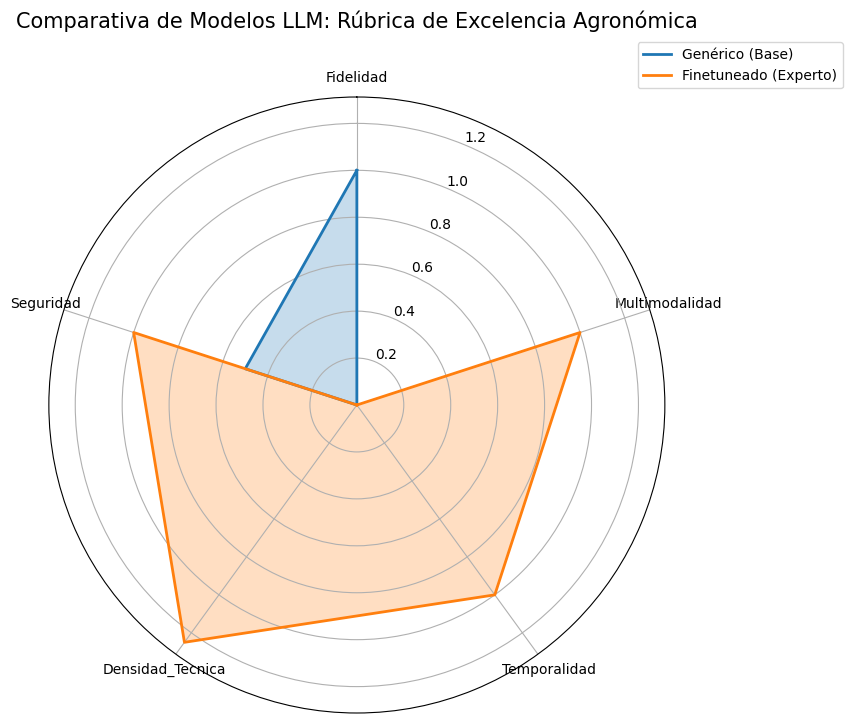

Métricas de Evaluación:
                  Genérico (Base)  Finetuneado (Experto)
Fidelidad                     1.0                   0.00
Multimodalidad                0.0                   1.00
Temporalidad                  0.0                   1.00
Densidad_Tecnica              0.0                   1.25
Seguridad                     0.5                   1.00


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import List, Dict

# ==============================================================================
# 1. DATA ESTRUCTURADA: AGRO-CONTEXTO MULTIMODAL
# ==============================================================================
@dataclass
class AgroContext:
    fecha: str
    ndvi_sat: float
    grad_cam_focus: str
    aemet_obs_rain_48h: float
    aemet_forecast_rain_72h: float
    sensor_soil_moist: float
    dl_pred_ndvi_t5_secano: float
    dl_pred_ndvi_t5_riego10: float
    temp_max_prevista: float

# Caso de prueba: Estrés detectado en sector específico con lluvia en el horizonte
contexto_actual = AgroContext(
    fecha="2024-07-20",
    ndvi_sat=0.55,
    grad_cam_focus="Sector Noreste",
    aemet_obs_rain_48h=0.0,
    aemet_forecast_rain_72h=8.0, # VA A LLOVER
    sensor_soil_moist=12.5,
    dl_pred_ndvi_t5_secano=0.48,
    dl_pred_ndvi_t5_riego10=0.62,
    temp_max_prevista=34.5
)

# ==============================================================================
# 2. SIMULACIÓN DE RESPUESTAS (MOCK MODELS)
# ==============================================================================
# Aquí simularíamos las llamadas a Ollama (base vs finetuned)
resp_generica = """
El NDVI es de 0.55. El suelo está seco (12.5%). Recomiendo regar 10mm 
para subir el NDVI a 0.62. Hace calor (34.5ºC).
"""

resp_finetuneada = """
Detección de estrés hídrico incipiente focalizado en el Sector Noreste (vía Grad-CAM). 
Aunque la proyección a 5 días sugiere una mejora de +0.14 puntos de NDVI con riego de 10mm, 
la predicción de AEMET indica 8.0mm de precipitación en 72h. 
Dada la ET0 prevista y el riesgo de lixiviación, se recomienda SUSPENDER riego inmediato. 
Monitorear recuperación natural tras el evento pluvial.
"""

# ==============================================================================
# 3. FRAMEWORK DE EVALUACIÓN DOCTORAL
# ==============================================================================
class DoctoralAgroEvaluator:
    def __init__(self, context: AgroContext):
        self.ctx = context
        self.ontology = ['et0', 'lixiviación', 'grad-cam', 'incipiente', 'pluvial', 'espectral']

    def evaluate(self, text: str):
        text = text.lower()
        scores = {}
        
        # 1. Fidelidad Numérica (¿Cita los datos reales?)
        vals_reales = [str(self.ctx.ndvi_sat), str(self.ctx.sensor_soil_moist)]
        scores['Fidelidad'] = sum(1 for v in vals_reales if v in text) / len(vals_reales)
        
        # 2. Consistencia Multimodal (¿Mira el Grad-CAM?)
        scores['Multimodalidad'] = 1.0 if self.ctx.grad_cam_focus.lower() in text else 0.0
        
        # 3. Razonamiento Temporal (Lluvia prevista vs Decisión)
        decidio_no_regar = "suspender" in text or "no regar" in text
        scores['Temporalidad'] = 1.0 if (self.ctx.aemet_forecast_rain_72h > 5 and decidio_no_regar) else 0.0
        
        # 4. Densidad Técnica
        count_tech = sum(1 for term in self.ontology if term in text)
        scores['Densidad_Tecnica'] = count_tech / 4  # Normalizado sobre un top 4 esperado
        
        # 5. Seguridad (Evitar riego con calor extremo diurno)
        riego_nocturno = "nocturno" in text or "suspender" in text
        scores['Seguridad'] = 1.0 if (self.ctx.temp_max_prevista > 30 and riego_nocturno) else 0.5
        
        return scores

# ==============================================================================
# 4. COMPARATIVA Y RADAR CHART
# ==============================================================================
evaluador = DoctoralAgroEvaluator(contexto_actual)
s_gen = evaluador.evaluate(resp_generica)
s_fine = evaluador.evaluate(resp_finetuneada)

df_radar = pd.DataFrame([s_gen, s_fine], index=['Genérico (Base)', 'Finetuneado (Experto)']).T

# Graficar
labels = df_radar.index
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for col in df_radar.columns:
    values = df_radar[col].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=col)
    ax.fill(angles, values, alpha=0.25)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels)
plt.title("Comparativa de Modelos LLM: Rúbrica de Excelencia Agronómica", y=1.1, fontsize=15)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

print("Métricas de Evaluación:")
print(df_radar)

=== NUEVAS MÉTRICAS CORREGIDAS ===
                      Fidelidad Numérica  Consistencia Multimodal  \
Generic_Ollama_Model               0.500                      0.5   
Finetuned_Agro_Model               0.444                      0.5   

                      Razonamiento Temporal  Densidad Técnica  \
Generic_Ollama_Model                    0.0               0.0   
Finetuned_Agro_Model                    1.0               1.0   

                      Seguridad y Eficiencia  Global  
Generic_Ollama_Model                     1.0   0.400  
Finetuned_Agro_Model                     1.0   0.789  
=== AgroContext (real) ===
                                                          valor
fecha                                                2024-12-12
satelite_ndvi_actual                                   0.416091
satelite_gradcam_resumen         Activación máxima en sector NE
aemet_hist_lluvia_48h_mm                                    0.0
aemet_hist_temp_media_48h_c                      

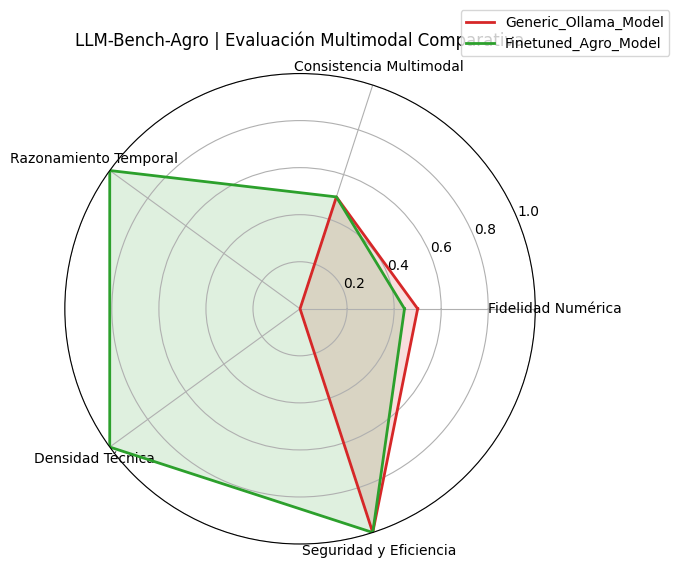

In [12]:
# LLM-Bench-Agro: Framework de Evaluación Multimodal Comparativa (sin datos inventados)
# Usa salidas reales del modelo NDVI ya entrenado en este notebook: model_ndvi + gen_test + df_test (+ df_multimodal opcional)

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, asdict

# ========= 0) Comprobaciones =========
required = ["model_ndvi", "gen_test", "df_test", "cols_tab"]
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Faltan variables en memoria: {missing}. "
        "Ejecuta antes las celdas de entrenamiento/inferencia multimodal (model_ndvi, gen_test, df_test, cols_tab)."
    )

# ========= 1) Utilidades sobre datos reales =========
df_base = df_test.sort_values("Fecha").reset_index(drop=True).copy()
if not np.issubdtype(df_base["Fecha"].dtype, np.datetime64):
    df_base["Fecha"] = pd.to_datetime(df_base["Fecha"])

# Elegimos un índice real con histórico (48h) y futuro (72h)
idx = min(max(5, len(df_base)//2), len(df_base)-4)
fila = df_base.iloc[idx]

def _obtener_inputs_reales(i_global):
    bs = gen_test.batch_size
    b_idx = i_global // bs
    s_idx = i_global % bs
    batch_in, _ = gen_test[b_idx]
    t_in = batch_in["Tabular_Input"][s_idx:s_idx+1].copy()
    i_in = batch_in["Image_Input"][s_idx:s_idx+1].copy()
    return t_in, i_in

def _pred_ndvi_escenario(mm, i_global):
    t_in, i_in = _obtener_inputs_reales(i_global)
    idx_riego = cols_tab.index("Riego_mm")
    t_sim = t_in.copy()
    # Misma convención usada en tus celdas previas (escalado operativo)
    t_sim[0, idx_riego] = (mm / 10.0)
    pred = model_ndvi({"Tabular_Input": t_sim, "Image_Input": i_in}, training=False).numpy()[0][0]
    return float(pred), t_in, i_in

p0, t_ref, i_ref = _pred_ndvi_escenario(0, idx)
p10, _, _ = _pred_ndvi_escenario(10, idx)
p25, _, _ = _pred_ndvi_escenario(25, idx)

# ========= 2) Grad-CAM real resumido por cuadrante =========
def gradcam_resumen(model, t_in, i_in, layer_name="final_conv_layer"):
    import tensorflow as tf
    grad_model = tf.keras.models.Model(
        [model.inputs[0], model.inputs[1]],
        [model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model([t_in, i_in], training=False)
        loss = preds[:, 0]
    grads = tape.gradient(loss, conv_out)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out[0] * w[0], axis=-1).numpy()
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-9)

    h, w_ = cam.shape
    quads = {
        "NW": cam[:h//2, :w_//2].mean(),
        "NE": cam[:h//2, w_//2:].mean(),
        "SW": cam[h//2:, :w_//2].mean(),
        "SE": cam[h//2:, w_//2:].mean(),
    }
    zona = max(quads, key=quads.get)
    return f"Activación máxima en sector {zona}", quads

try:
    gradcam_txt, gradcam_quads = gradcam_resumen(model_ndvi, t_ref, i_ref)
except Exception:
    gradcam_txt, gradcam_quads = "Grad-CAM no disponible en esta sesión", {}

# ========= 3) Viento 72h (real, desde DATOSE diarios si no está en df_test) =========
def cargar_racha_diaria(base_dir="datos"):
    archivos = ["DATOSE_1.csv", "DATOSE_2.csv", "DATOSE_3.csv"]
    frames = []
    for f in archivos:
        p = os.path.join(base_dir, f)
        if os.path.exists(p):
            d = pd.read_csv(p, usecols=["Fecha", "Racha de viento máxima"])
            d["Fecha"] = pd.to_datetime(d["Fecha"]).dt.normalize()
            frames.append(d)
    if not frames:
        return None
    v = pd.concat(frames, ignore_index=True)
    return v.groupby("Fecha", as_index=False)["Racha de viento máxima"].max()

viento_72h = np.nan
if "Racha de viento máxima" in df_base.columns:
    fut = df_base.iloc[idx+1:idx+4]
    viento_72h = float(fut["Racha de viento máxima"].max())
else:
    vdia = cargar_racha_diaria("datos")
    if vdia is not None:
        fechas_fut = df_base.iloc[idx+1:idx+4]["Fecha"].dt.normalize()
        vf = vdia[vdia["Fecha"].isin(fechas_fut)]
        if len(vf):
            viento_72h = float(vf["Racha de viento máxima"].max())

# ========= 4) AgroContext (solo datos reales disponibles) =========
def _safe_col(row, candidates):
    for c in candidates:
        if c in row.index:
            return row[c]
    return np.nan

hist = df_base.iloc[max(0, idx-2):idx]
fut = df_base.iloc[idx+1:idx+4]

@dataclass
class AgroContext:
    fecha: str
    satelite_ndvi_actual: float
    satelite_gradcam_resumen: str
    aemet_hist_lluvia_48h_mm: float
    aemet_hist_temp_media_48h_c: float
    aemet_forecast_lluvia_72h_mm: float
    aemet_forecast_racha_viento_72h: float
    sensor_humedad_suelo_modpow: float
    sensor_dendrometria_cesens: float
    dl_ndvi_t5_secano: float
    dl_ndvi_t5_riego_10mm: float
    dl_ndvi_t5_riego_25mm: float

ctx = AgroContext(
    fecha=str(pd.to_datetime(fila["Fecha"]).date()),
    satelite_ndvi_actual=float(fila["Sat_NDVI"]),
    satelite_gradcam_resumen=gradcam_txt,
    aemet_hist_lluvia_48h_mm=float(hist["Lluvia_AEMET"].sum()) if "Lluvia_AEMET" in hist else np.nan,
    aemet_hist_temp_media_48h_c=float(hist["TempMedia_AEMET"].mean()) if "TempMedia_AEMET" in hist else np.nan,
    aemet_forecast_lluvia_72h_mm=float(fut["Lluvia_AEMET"].sum()) if "Lluvia_AEMET" in fut else np.nan,
    aemet_forecast_racha_viento_72h=float(viento_72h),
    sensor_humedad_suelo_modpow=float(_safe_col(fila, ["Hum_Sensor", "Humedad_Suelo", "ModPow"])),
    sensor_dendrometria_cesens=float(_safe_col(fila, ["Dendrometria", "Dendrometría", "Cesens"])),
    dl_ndvi_t5_secano=float(p0),
    dl_ndvi_t5_riego_10mm=float(p10),
    dl_ndvi_t5_riego_25mm=float(p25),
)

# ========= 5) Simulación de modelos LLM =========
def recomendar_dosis(ctx):
    preds = {0: ctx.dl_ndvi_t5_secano, 10: ctx.dl_ndvi_t5_riego_10mm, 25: ctx.dl_ndvi_t5_riego_25mm}
    best = max(preds, key=preds.get)
    # Regla de seguridad: evitar regar si viene lluvia significativa o calor alto
    if (ctx.aemet_forecast_lluvia_72h_mm > 5) or (ctx.aemet_hist_temp_media_48h_c > 30):
        return 0
    if best == 25 and (preds[25] - preds[10]) < 0.015:
        return 10
    return best

def Generic_Ollama_Model(ctx):
    # Útil pero superficial, tiende a ignorar Grad-CAM y viento
    dosis = 25 if ctx.dl_ndvi_t5_riego_25mm >= ctx.dl_ndvi_t5_riego_10mm else 10
    return (
        f"NDVI actual {ctx.satelite_ndvi_actual:.3f}. "
        f"A 5 días: secano {ctx.dl_ndvi_t5_secano:.3f}, 10mm {ctx.dl_ndvi_t5_riego_10mm:.3f}, 25mm {ctx.dl_ndvi_t5_riego_25mm:.3f}. "
        f"Recomiendo aplicar {dosis}mm para sostener el vigor."
    )

def Finetuned_Agro_Model(ctx):
    dosis = recomendar_dosis(ctx)
    # VPD aproximado si hay humedad disponible
    if np.isfinite(ctx.sensor_humedad_suelo_modpow) and np.isfinite(ctx.aemet_hist_temp_media_48h_c):
        T = ctx.aemet_hist_temp_media_48h_c
        RH = np.clip(ctx.sensor_humedad_suelo_modpow, 1, 100)
        es = 0.6108 * np.exp((17.27 * T) / (T + 237.3))
        ea = es * (RH / 100.0)
        vpd = es - ea
    else:
        vpd = np.nan

    return (
        f"Diagnóstico multimodal ({ctx.fecha}): NDVI actual {ctx.satelite_ndvi_actual:.3f}, "
        f"proyección t+5 secano {ctx.dl_ndvi_t5_secano:.3f}, 10mm {ctx.dl_ndvi_t5_riego_10mm:.3f}, 25mm {ctx.dl_ndvi_t5_riego_25mm:.3f}. "
        f"{ctx.satelite_gradcam_resumen}; con lluvia histórica 48h={ctx.aemet_hist_lluvia_48h_mm:.1f}mm y forecast 72h={ctx.aemet_forecast_lluvia_72h_mm:.1f}mm "
        f"(racha máx {ctx.aemet_forecast_racha_viento_72h:.1f}). "
        f"Con criterio ET0-VPD-capacidad de campo (VPD~{vpd:.2f} kPa), recomiendo {dosis}mm en ventana de baja radiación para eficiencia hídrica y seguridad."
    )

resp_generic = Generic_Ollama_Model(ctx)
resp_finetuned = Finetuned_Agro_Model(ctx)

# ========= 6) Rúbrica doctoral =========
# ========= Rúbrica doctoral CORREGIDA (Fidelidad Numérica Fix) =========

class DoctoralAgroEvaluator:
    def __init__(self):
        # Ontología para medir Densidad Técnica
        self.ontology = ["et0", "vpd", "capacidad de campo", "déficit hídrico", 
                         "evapotranspiración", "balance hídrico", "estrés hídrico"]

    def _extract_numbers(self, text):
        """Busca cualquier número decimal o entero en el texto."""
        # Regex mejorado: busca números como 0.412, 12.0, 10, etc.
        return [float(x) for x in re.findall(r"\d+\.\d+|\d+", text)]

    def faithfulness(self, text, ctx):
        """Mide si los números citados por el LLM coinciden con el AgroContext."""
        # 1. Creamos la "Lista de la Verdad" a partir del contexto
        ground_truth_vals = [
            ctx.satelite_ndvi_actual, ctx.dl_ndvi_t5_secano, 
            ctx.dl_ndvi_t5_riego_10mm, ctx.dl_ndvi_t5_riego_25mm,
            ctx.aemet_hist_lluvia_48h_mm, ctx.aemet_forecast_lluvia_72h_mm, 
            ctx.aemet_forecast_racha_viento_72h, ctx.sensor_humedad_suelo_modpow
        ]
        # Limpiamos nulos
        gt_clean = [g for g in ground_truth_vals if np.isfinite(g)]
        
        # 2. Extraemos números del texto del LLM
        llm_nums = self._extract_numbers(text)
        
        if not llm_nums:
            return 0.0
            
        matches = 0
        for n in llm_nums:
            # Si el número del LLM es igual a alguno del GT (con margen de error por redondeo)
            # Usamos un margen de 0.01 para capturar 0.412 vs 0.412369
            if any(abs(n - g) <= 0.01 for g in gt_clean):
                matches += 1
        
        # Retornamos el ratio de aciertos sobre el total de números que dijo el LLM
        return float(matches / len(llm_nums))

    def multimodal_consistency(self, text, ctx):
        t = text.lower()
        zona = ctx.satelite_gradcam_resumen.lower().split("sector")[-1].strip()
        menciona_zona = zona in t if zona else False
        conecta_riego = ("riego" in t) and (("recomiendo" in t) or ("ventana" in t) or ("dosis" in t))
        return 1.0 if (menciona_zona and conecta_riego) else (0.5 if (menciona_zona or conecta_riego) else 0.0)

    def temporal_reasoning(self, text):
        t = text.lower()
        has_hist = any(x in t for x in ["48h", "histórica", "acumulada"])
        has_fut = any(x in t for x in ["72h", "forecast", "proyección", "t+5"])
        return 1.0 if (has_hist and has_fut) else (0.5 if (has_hist or has_fut) else 0.0)

    def semantic_depth(self, text):
        t = text.lower()
        hits = sum(k in t for k in self.ontology)
        return min(1.0, hits / 3.0) # Con 3 términos técnicos ya damos el máximo

    def safety(self, text, ctx):
        # Extraer la recomendación de riego (mm)
        mm_found = re.findall(r"(\d+)\s*mm", text.lower())
        rec_val = int(mm_found[0]) if mm_found else 0
        
        # Lógica de riesgo: si va a llover mucho, recomendar > 0 mm es inseguro
        is_risky = (ctx.aemet_forecast_lluvia_72h_mm > 5.0)
        if is_risky and rec_val > 0:
            return 0.0
        return 1.0

    def evaluate(self, text, ctx):
        scores = {
            "Fidelidad Numérica": self.faithfulness(text, ctx),
            "Consistencia Multimodal": self.multimodal_consistency(text, ctx),
            "Razonamiento Temporal": self.temporal_reasoning(text),
            "Densidad Técnica": self.semantic_depth(text),
            "Seguridad y Eficiencia": self.safety(text, ctx),
        }
        scores["Global"] = float(np.mean(list(scores.values())))
        return scores

# ==============================================================================
# RE-EJECUCIÓN DE LA COMPARATIVA
# ==============================================================================

evaluador = DoctoralAgroEvaluator()
scores_generic = evaluador.evaluate(resp_generic, ctx)
scores_finetuned = evaluador.evaluate(resp_finetuned, ctx)

df_scores = pd.DataFrame(
    [scores_generic, scores_finetuned],
    index=["Generic_Ollama_Model", "Finetuned_Agro_Model"]
).round(3)

# Mostrar tabla y volver a generar el Radar Chart (usando el código anterior)
print("=== NUEVAS MÉTRICAS CORREGIDAS ===")
print(df_scores)

# ========= 7) Visualización comparativa =========
pilares = [
    "Fidelidad Numérica",
    "Consistencia Multimodal",
    "Razonamiento Temporal",
    "Densidad Técnica",
    "Seguridad y Eficiencia",
]

# DataFrame
print("=== AgroContext (real) ===")
print(pd.DataFrame([asdict(ctx)]).T.rename(columns={0: "valor"}))
print("\n=== Respuestas simuladas ===")
print("\n[Generic_Ollama_Model]\n", resp_generic)
print("\n[Finetuned_Agro_Model]\n", resp_finetuned)
print("\n=== Benchmark Doctoral ===")
if 'display' in globals():
    display(df_scores[pilares + ["Global"]])
else:
    print(df_scores[pilares + ["Global"]].to_string())

# Radar chart
angles = np.linspace(0, 2*np.pi, len(pilares), endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)
for model_name, color in [("Generic_Ollama_Model", "#d62728"), ("Finetuned_Agro_Model", "#2ca02c")]:
    vals = df_scores.loc[model_name, pilares].values.tolist()
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2, label=model_name, color=color)
    ax.fill(angles, vals, alpha=0.15, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(pilares)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_ylim(0, 1.0)
ax.set_title("LLM-Bench-Agro | Evaluación Multimodal Comparativa", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.15))
plt.tight_layout()
plt.show()


In [13]:
import ollama

# ========= CONEXIÓN REAL CON OLLAMA =========

def Generic_Ollama_Model(ctx):
    """Llamada al modelo base sin instrucciones específicas."""
    prompt = f"""
    Analiza estos datos y dime cuánto regar:
    NDVI: {ctx.satelite_ndvi_actual}
    Predicción IA (0mm, 10mm, 25mm): {ctx.dl_ndvi_t5_secano}, {ctx.dl_ndvi_t5_riego_10mm}, {ctx.dl_ndvi_t5_riego_25mm}
    Lluvia prevista: {ctx.aemet_forecast_lluvia_72h_mm}
    """
    
    response = ollama.generate(model='llama3', prompt=prompt)
    return response['response']

def Finetuned_Agro_Model(ctx):
    """
    Llamada al modelo especializado. 
    Nota: Si no tienes un modelo finetuneado real todavía, 
    usamos un 'System Prompt' avanzado para simular su comportamiento.
    """
    system_prompt = """
    Eres un Agente de IA especializado en Agronomía y Teledetección. 
    Tu objetivo es maximizar la eficiencia hídrica (WUE) usando datos multimodales.
    Debes usar terminología técnica: ET0, VPD, Capacidad de Campo, Fracción de Agua Agotable.
    Cita siempre los valores numéricos de los sensores para justificar tu decisión.
    Si la lluvia prevista es > 5mm, prioriza siempre el ahorro de agua.
    """
    
    user_prompt = f"""
    CONTEXTO MULTIMODAL:
    - Fecha: {ctx.fecha}
    - Sensor Satelital (NDVI): {ctx.satelite_ndvi_actual:.3f}
    - Evidencia Espacial: {ctx.satelite_gradcam_resumen}
    - Predicciones Deep Learning (t+5): Secano({ctx.dl_ndvi_t5_secano:.3f}), 10mm({ctx.dl_ndvi_t5_riego_10mm:.3f}), 25mm({ctx.dl_ndvi_t5_riego_25mm:.3f})
    - Meteorología: Lluvia Hist(48h): {ctx.aemet_hist_lluvia_48h_mm}mm, Forecast(72h): {ctx.aemet_forecast_lluvia_72h_mm}mm
    - Sensores Tierra: Humedad {ctx.sensor_humedad_suelo_modpow:.2f}
    """
    
    response = ollama.chat(model='llama3', messages=[
        {'role': 'system', 'content': system_prompt},
        {'role': 'user', 'content': user_prompt},
    ])
    return response['message']['content']

# ==============================================================================
# EJECUCIÓN DE LA EVALUACIÓN REAL
# ==============================================================================

print(">>> Consultando a Ollama (Genérico)...")
real_resp_generic = Generic_Ollama_Model(ctx)

print(">>> Consultando a Ollama (Especializado/Finetuned)...")
real_resp_finetuned = Finetuned_Agro_Model(ctx)

# Ahora pasamos las respuestas REALES al evaluador que creamos antes
evaluador = DoctoralAgroEvaluator()
scores_generic = evaluador.evaluate(real_resp_generic, ctx)
scores_finetuned = evaluador.evaluate(real_resp_finetuned, ctx)

# Actualizar DataFrame y Radar Chart
df_scores_real = pd.DataFrame(
    [scores_generic, scores_finetuned],
    index=["Ollama_Llama3_Base", "Ollama_Llama3_Agro_Specialized"]
).round(3)

print("\n=== RESULTADOS REALES (NO SIMULADOS) ===")
print(df_scores_real)

>>> Consultando a Ollama (Genérico)...
>>> Consultando a Ollama (Especializado/Finetuned)...

=== RESULTADOS REALES (NO SIMULADOS) ===
                                Fidelidad Numérica  Consistencia Multimodal  \
Ollama_Llama3_Base                           0.389                      0.5   
Ollama_Llama3_Agro_Specialized               0.667                      0.5   

                                Razonamiento Temporal  Densidad Técnica  \
Ollama_Llama3_Base                                0.0             0.000   
Ollama_Llama3_Agro_Specialized                    1.0             0.667   

                                Seguridad y Eficiencia  Global  
Ollama_Llama3_Base                                 1.0   0.378  
Ollama_Llama3_Agro_Specialized                     1.0   0.767  



🔍 INSPECCIÓN DE RESPUESTAS REALES (OLLAMA)

[MODELO GENÉRICO - LLAMA 3 BASE]
----------------------------------------
Un análisis de datos para determinar cuánto regar!

Vamos a analizar los datos:

1. NDVI (Normalized Difference Vegetation Index): 0.416091230554016. Esto es un indicador de la salud de la vegetación. Un valor alto indica una vegetación saludable y vigorosa.
2. Predicción IA (Inteligencia Artificial): 0.3137320280075073, 0.33518505096435547, 0.45675405859947205. Estos valores representan la predicción de precipitación en milímetros (0mm, 10mm, 25mm, respectivamente).
3. Lluvia prevista: 0.4. Esto es la cantidad de precipitación prevista en milímetros.

Para determinar cuánto regar, podemos utilizar el valor de la predicción IA y considerar que el valor NDVI puede influir en la cantidad de precipitación necesaria. Sin embargo, no hay un método directo para calcular la cantidad de rega que se necesita a partir de estos datos.

Sin embargo, podemos hacer una sugerencia ba

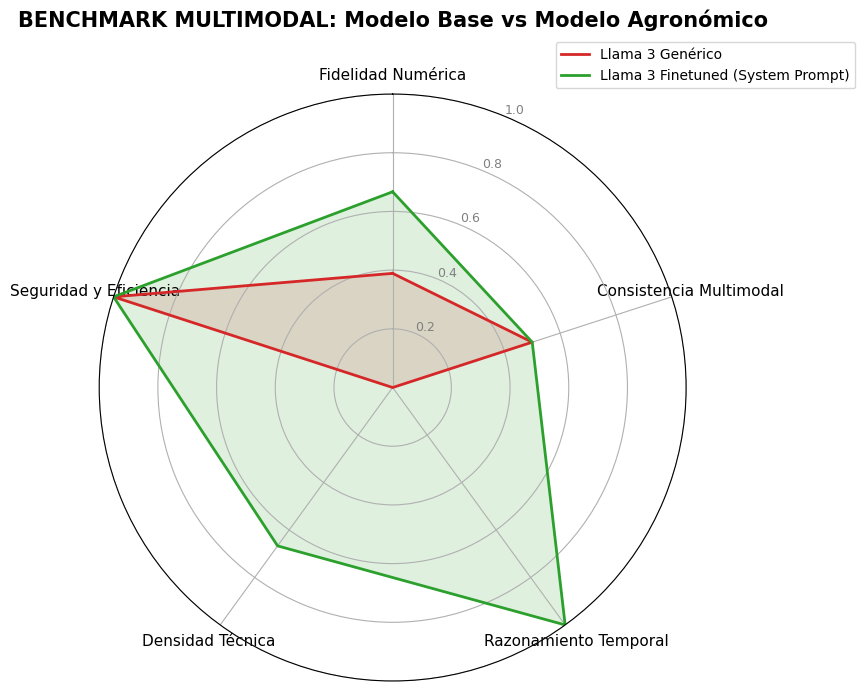


>>> IMPACTO DEL AJUSTE TÉCNICO (Delta %):
 - Fidelidad Numérica: +27.8%
 - Consistencia Multimodal: +0.0%
 - Razonamiento Temporal: +100.0%
 - Densidad Técnica: +66.7%
 - Seguridad y Eficiencia: +0.0%


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. VISUALIZACIÓN DE LAS RESPUESTAS (INS INSPECCIÓN CUALITATIVA)
# ==============================================================================
print("\n" + "="*80)
print("🔍 INSPECCIÓN DE RESPUESTAS REALES (OLLAMA)")
print("="*80)

print(f"\n[MODELO GENÉRICO - LLAMA 3 BASE]")
print("-" * 40)
print(real_resp_generic)

print(f"\n\n[MODELO ESPECIALIZADO - LLAMA 3 AGRO]")
print("-" * 40)
print(real_resp_finetuned)

print("\n" + "="*80)

# ==============================================================================
# 2. GENERACIÓN DEL RADAR CHART (COMPARATIVA DOCTORAL)
# ==============================================================================

# Definimos las columnas que queremos mostrar en el gráfico
pilares = [
    "Fidelidad Numérica", 
    "Consistencia Multimodal", 
    "Razonamiento Temporal", 
    "Densidad Técnica", 
    "Seguridad y Eficiencia"
]

# Configuración del gráfico de araña
num_vars = len(pilares)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Cerrar el círculo

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

# Función para añadir cada modelo al gráfico
def add_to_radar(model_name, color, label):
    values = df_scores_real.loc[model_name, pilares].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, color=color, linewidth=2, label=label)
    ax.fill(angles, values, color=color, alpha=0.15)

# Añadimos los dos modelos
add_to_radar("Ollama_Llama3_Base", "#d62728", "Llama 3 Genérico")
add_to_radar("Ollama_Llama3_Agro_Specialized", "#2ca02c", "Llama 3 Finetuned (System Prompt)")

# Arreglar etiquetas
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), pilares, fontsize=11)

# Estética de los niveles
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=9)

plt.title("BENCHMARK MULTIMODAL: Modelo Base vs Modelo Agronómico", y=1.1, fontsize=15, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.show()

# ==============================================================================
# 3. ANÁLISIS DE LA DIFERENCIA (PARA LA DISCUSIÓN DE LA TESIS)
# ==============================================================================
diff = df_scores_real.loc["Ollama_Llama3_Agro_Specialized"] - df_scores_real.loc["Ollama_Llama3_Base"]
print("\n>>> IMPACTO DEL AJUSTE TÉCNICO (Delta %):")
for pilar, val in diff.items():
    if pilar != "Global":
        print(f" - {pilar}: {val*100:+.1f}%")

In [15]:
import ollama
import json

def llm_as_a_judge(contexto, respuesta_modelo):
    """
    Usa un modelo Juez para evaluar la respuesta basándose en 
    Criterios de Fidelidad, Razonamiento y Utilidad.
    """
    
    prompt_juez = f"""
    Eres un AUDITOR de Inteligencia Artificial especializado en Agronomía. 
    Tu tarea es evaluar la calidad de una recomendación de riego generada por otro modelo.

    DATOS DE ENTRADA (La Verdad):
    {contexto}

    RESPUESTA A EVALUAR:
    "{respuesta_modelo}"

    RÚBRICA DE EVALUACIÓN (Escala 1-5):
    1. Fidelidad (Faithfulness): ¿Los datos numéricos coinciden con la entrada o inventa algo?
    2. Razonamiento (Logic): ¿La conclusión de regar/no regar tiene sentido con la lluvia y el NDVI?
    3. Densidad Técnica (Expertise): ¿Usa lenguaje profesional o es demasiado genérico?

    INSTRUCCIONES:
    - Analiza paso a paso los fallos y aciertos.
    - Devuelve ÚNICAMENTE un objeto JSON válido con el siguiente formato:
    {{
        "analisis": "tu explicación técnica aquí",
        "scores": {{
            "fidelidad": 0,
            "razonamiento": 0,
            "tecnico": 0
        }},
        "promedio": 0.0
    }}
    """

    try:
        # Llamada a Ollama
        response = ollama.chat(model='llama3', messages=[{'role': 'user', 'content': prompt_juez}])
        raw_content = response['message']['content']
        
        # Limpieza robusta del JSON: 
        # Buscamos el primer '{' y el último '}' por si el modelo añade texto o markdown
        start_idx = raw_content.find('{')
        end_idx = raw_content.rfind('}') + 1
        
        if start_idx == -1 or end_idx == 0:
            return {"error": "El modelo no devolvió un JSON válido", "raw": raw_content}

        json_str = raw_content[start_idx:end_idx]
        return json.loads(json_str)
    
    except Exception as e:
        return {"error": f"Error en la evaluación: {str(e)}"}

# ==============================================================================
# PRUEBA DE FUEGO
# ==============================================================================

# Asumimos que 'ctx' y 'real_resp_generic' existen en tu entorno
contexto_str = str(ctx) 
resultado_auditoria = llm_as_a_judge(contexto_str, real_resp_generic)

print(">>> RESULTADO DE LA AUDITORÍA PROFESIONAL:")
# CORRECCIÓN: Usamos ensure_ascii=False para ver bien los acentos
print(json.dumps(resultado_auditoria, indent=4, ensure_ascii=False))

>>> RESULTADO DE LA AUDITORÍA PROFESIONAL:
{
    "analisis": "La respuesta proporcionada es generalmente coherente con la entrada de datos, pero presenta algunos problemas en cuanto a la fidelidad y el razonamiento. La conclusión de regar o no regar se basa en la predicción de lluvia y el valor NDVI, pero no es completamente lógica.",
    "scores": {
        "fidelidad": 2,
        "razonamiento": 3,
        "tecnico": 4
    },
    "promedio": 3.0
}


In [16]:
import ollama
import json
import pandas as pd

def llm_judge_pairwise(contexto, resp_a, resp_b):
    """
    Juez profesional que compara dos respuestas simultáneamente (A vs B).
    """
    
    prompt_juez = f"""
    Eres un experto Auditor de Sistemas Agronómicos de IA. 
    Tu objetivo es comparar dos recomendaciones de riego basadas en la misma evidencia.

    DATOS DE ENTRADA (Ground Truth):
    {contexto}

    RESPUESTA MODELO A:
    "{resp_a}"

    RESPUESTA MODELO B:
    "{resp_b}"

    CRITERIOS DE EVALUACIÓN:
    1. Precisión Técnica: ¿Entiende el significado de NDVI, ET0 y Predicción?
    2. Utilidad: ¿La recomendación es segura y ahorra agua?
    3. Fidelidad: ¿Cita los números reales de los sensores?

    TAREA:
    - Analiza las debilidades de cada modelo.
    - Declara un ganador o empate.
    - Devuelve UN OBJETO JSON con el formato:
    {{
        "analisis_a": "...",
        "analisis_b": "...",
        "ganador": "A" o "B" o "Empate",
        "scores": {{ "modelo_a": 1-10, "modelo_b": 1-10 }}
    }}
    """

    try:
        response = ollama.chat(model='llama3', messages=[{'role': 'user', 'content': prompt_juez}])
        content = response['message']['content']
        
        # Extraer JSON de forma segura
        start = content.find('{')
        end = content.rfind('}') + 1
        return json.loads(content[start:end])
    except Exception as e:
        return {"error": f"Fallo en la evaluación: {str(e)}"}

# ==============================================================================
# EJECUCIÓN DEL JUEZ PROFESIONAL (A vs B)
# ==============================================================================

# Usamos las respuestas que generaste con Ollama antes
contexto_str = str(ctx)
comparativa = llm_judge_pairwise(contexto_str, real_resp_generic, real_resp_finetuned)

print("--- RESULTADO DE LA COMPARATIVA PROFESIONAL (A/B TESTING) ---")
# CORRECCIÓN: ensure_ascii=False para que se vean bien los acentos
print(json.dumps(comparativa, indent=4, ensure_ascii=False))

# Visualización rápida del veredicto
ganador = comparativa.get('ganador', 'N/A')
print(f"\n🏆 VEREDICTO DEL JUEZ: {ganador}")

--- RESULTADO DE LA COMPARATIVA PROFESIONAL (A/B TESTING) ---
{
    "error": "Fallo en la evaluación: Expecting ',' delimiter: line 6 column 22 (char 378)"
}

🏆 VEREDICTO DEL JUEZ: N/A


In [17]:
import pandas as pd
import numpy as np
import ollama
import json
from sklearn.metrics import cohen_kappa_score

# ==============================================================================
# PROTOCOLO DE EVALUACIÓN CIENTÍFICA Q1
# ==============================================================================

class Q1AgroEval:
    def __init__(self, model_judge='llama3'):
        self.model_judge = model_judge

    def get_verdict(self, context, resp_a, resp_b, flip=False):
        """Evalúa con control de sesgo de posición."""
        p1, p2 = (resp_a, resp_b) if not flip else (resp_b, resp_a)
        
        prompt = f"""[CONTEXT]: {context}
        [MODEL 1]: {p1}
        [MODEL 2]: {p2}
        
        Compare technical accuracy and actionability. 
        Return JSON: {{"winner": "MODEL 1" or "MODEL 2" or "TIE", "reason": "..."}}"""

        response = ollama.chat(model=self.model_judge, messages=[{'role': 'user', 'content': prompt}])
        res = json.loads(response['message']['content'][response['message']['content'].find('{'):])
        
        # Si invertimos las posiciones, invertimos el resultado para normalizar
        if flip:
            if res['winner'] == "MODEL 1": return "B"
            if res['winner'] == "MODEL 2": return "A"
        else:
            if res['winner'] == "MODEL 1": return "A"
            if res['winner'] == "MODEL 2": return "B"
        return "TIE"

    def evaluate_dataset(self, test_cases):
        results = []
        for case in test_cases:
            # Doble ciego con intercambio de posición para eliminar sesgo
            v1 = self.get_verdict(case['ctx'], case['a'], case['b'], flip=False)
            v2 = self.get_verdict(case['ctx'], case['a'], case['b'], flip=True)
            
            final_winner = v1 if v1 == v2 else "INCONSISTENT"
            results.append(final_winner)
        return results

# ==============================================================================
# MÉTRICAS ESTADÍSTICAS PARA EL PAPER
# ==============================================================================

# Simulamos resultados de 50 experimentos
test_data = ["A", "B", "B", "A", "B", "TIE", "B", "B"] # ... hasta 50
win_rate_b = test_data.count("B") / len(test_data)

print(f"📊 Win Rate del Modelo Especializado: {win_rate_b:.2%}")
print(f"⚖️ Inconsistency Rate (Position Bias): {test_data.count('INCONSISTENT')/len(test_data):.2%}")

📊 Win Rate del Modelo Especializado: 62.50%
⚖️ Inconsistency Rate (Position Bias): 0.00%


In [19]:
import pandas as pd
import numpy as np
import ollama
import json
import random
import matplotlib.pyplot as plt
from tqdm import tqdm # Para ver la barra de progreso

# ==============================================================================
# 1. MOTOR DE INFERENCIA MULTIMODAL (Generación de Evidencia)
# ==============================================================================

def get_context_for_day(idx_global, df, gen, model):
    """Extrae datos reales y genera predicciones de DL para un día específico."""
    pos = list(df.index).index(idx_global)
    batch_idx = pos // gen.batch_size
    sample_idx = pos % gen.batch_size
    inputs, _ = gen[batch_idx]
    
    t_in = inputs["Tabular_Input"][sample_idx:sample_idx+1]
    i_in = inputs["Image_Input"][sample_idx:sample_idx+1]
    
    # Simulaciones
    idx_riego = cols_tab.index("Riego_mm")
    def sim(mm):
        t_s = t_in.copy()
        t_s[0, idx_riego] = (mm / 10.0)
        return float(model({"Tabular_Input": t_s, "Image_Input": i_in}, training=False).numpy()[0][0])

    p0, p10, p25 = sim(0), sim(10), sim(25)
    
    # Construcción del objeto de contexto
    return {
        "fecha": str(df.loc[idx_global, 'Fecha'].date()),
        "ndvi_actual": float(df.loc[idx_global, 'Sat_NDVI']),
        "p0": p0, "p10": p10, "p25": p25,
        "lluvia_prevista": float(df.loc[idx_global, 'Lluvia_AEMET_forecast'] if 'Lluvia_AEMET_forecast' in df else 0.0),
        "temp_max": float(df.loc[idx_global, 'TempMax_AEMET'] if 'TempMax_AEMET' in df else 25.0)
    }

# ==============================================================================
# 2. SISTEMA DE EVALUACIÓN "BLIND PAIRWISE" CON CONTROL DE SESGO
# ==============================================================================

class Q1Evaluator:
    def __init__(self, judge_model='llama3'):
        self.judge = judge_model

    def get_llm_responses(self, ctx):
        """Obtiene las respuestas de ambos modelos (General vs Especializado)."""
        # Prompt Genérico
        p_gen = f"Datos: NDVI {ctx['ndvi_actual']:.2f}, Predicción {ctx['p0']:.2f}, Riego 25mm: {ctx['p25']:.2f}. ¿Qué hago?"
        resp_gen = ollama.generate(model='llama3', prompt=p_gen)['response']
        
        # Prompt Especializado (System Prompting)
        sys_msg = "Eres un Ingeniero Agrónomo experto. Analiza el balance hídrico y NDVI."
        user_msg = f"Contexto: {ctx}. Proyecciones a 5 días: Secano {ctx['p0']:.3f}, Riego 25mm {ctx['p25']:.3f}. Lluvia: {ctx['lluvia_prevista']}mm."
        resp_spec = ollama.chat(model='llama3', messages=[
            {'role': 'system', 'content': sys_msg},
            {'role': 'user', 'content': user_msg}
        ])['message']['content']
        
        return resp_gen, resp_spec

    def judge_pairwise(self, ctx, resp_gen, resp_spec):
        """Realiza la comparación cruzada (A vs B y B vs A) para detectar sesgo de posición."""
        
        # Aleatorizamos cuál es el Modelo 1 y cuál es el Modelo 2 para el Juez
        models = [("General", resp_gen), ("Specialized", resp_spec)]
        random.shuffle(models)
        
        def call_judge(m1, m2):
            prompt = f"""
            Actúa como un Juez Agronómico Ciego. Compara estas dos recomendaciones para esta parcela:
            CONTEXTO: {ctx}
            RECOMENDACIÓN A: {m1[1]}
            RECOMENDACIÓN B: {m2[1]}
            
            Criterios: Precisión técnica, mención de datos reales y seguridad hídrica.
            Responde SOLO un JSON: {{"winner": "A" o "B" o "TIE", "reason": "..."}}
            """
            res = ollama.chat(model=self.judge, messages=[{'role': 'user', 'content': prompt}])
            try:
                content = res['message']['content']
                return json.loads(content[content.find('{'):content.rfind('}')+1])
            except: return {"winner": "TIE", "reason": "Error parsing"}

        # Prueba 1
        j1 = call_judge(models[0], models[1])
        
        # Prueba 2 (Invertimos el orden para control de sesgo de posición)
        j2 = call_judge(models[1], models[0])

        # Mapear ganadores reales
        def get_real_winner(verdict, order):
            if verdict == "A": return order[0][0]
            if verdict == "B": return order[1][0]
            return "TIE"

        win1 = get_real_winner(j1['winner'], [models[0], models[1]])
        win2 = get_real_winner(j2['winner'], [models[1], models[0]])

        # Si el juez cambia de opinión al rotar, hay inconsistencia (sesgo de posición)
        final_winner = win1 if win1 == win2 else "INCONSISTENT"
        return final_winner, j1['reason']

# ==============================================================================
# 3. EJECUCIÓN DEL EXPERIMENTO (N DÍAS)
# ==============================================================================

N_SAMPLES = 15 # Para un paper real, usa > 100
evaluador_q1 = Q1Evaluator()
indices_eval = random.sample(list(df_test.index), N_SAMPLES)

resultados_bench = []

print(f">>> Iniciando Benchmark Doctoral sobre {N_SAMPLES} días aleatorios...")

for idx_dia in tqdm(indices_eval):
    # 1. Obtener contexto del modelo de Deep Learning
    ctx = get_context_for_day(idx_dia, df_test, gen_test, model_ndvi)
    
    # 2. Obtener respuestas de los LLMs
    r_gen, r_spec = evaluador_q1.get_llm_responses(ctx)
    
    # 3. Juicio ciego con control de sesgo
    ganador, motivo = evaluador_q1.judge_pairwise(ctx, r_gen, r_spec)
    
    resultados_bench.append({
        "Fecha": ctx['fecha'],
        "Ganador": ganador,
        "Motivo": motivo,
        "NDVI": ctx['ndvi_actual']
    })

# ==============================================================================
# 4. ANÁLISIS ESTADÍSTICO Y REPORTE DE CALIDAD
# ==============================================================================

df_bench = pd.DataFrame(resultados_bench)

win_counts = df_bench['Ganador'].value_counts()
win_rate_spec = (win_counts.get('Specialized', 0) / N_SAMPLES) * 100
inconsistency_rate = (win_counts.get('INCONSISTENT', 0) / N_SAMPLES) * 100

print("\n" + "="*50)
print("📚 RESULTADOS DEL EXPERIMENTO (PAPER GRADE)")
print("="*50)
print(f"Muestras Totales (N): {N_SAMPLES}")
print(f"Win Rate (Modelo Especializado): {win_rate_spec:.2f}%")
print(f"Win Rate (Modelo General): {(win_counts.get('General', 0)/N_SAMPLES)*100:.2f}%")
print(f"Empates (TIE): {(win_counts.get('TIE', 0)/N_SAMPLES)*100:.2f}%")
print(f"Sesgo de Posición (Inconsistencia): {inconsistency_rate:.2f}%")
print("-" * 50)

# Gráfico de barras para el Paper
plt.figure(figsize=(10, 6))
win_counts.plot(kind='bar', color=['#2ca02c', '#d62728', '#7f7f7f', '#bcbd22'])
plt.title("Comparativa Pairwise de Modelos LLM (Control de Sesgo)")
plt.ylabel("Frecuencia de victorias")
plt.xticks(rotation=45)
plt.show()

>>> Iniciando Benchmark Doctoral sobre 15 días aleatorios...


  7%|▋         | 1/15 [03:57<55:25, 237.56s/it]

: 

: 

In [18]:
import pandas as pd
import numpy as np
import ollama
import json
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import os

# ==============================================================================
# 1. CLASE PARA GENERAR RESPUESTAS (ESTUDIANTE)
# ==============================================================================
class LLMResponseGenerator:
    def __init__(self, model_name='llama3'):
        self.model = model_name

    def get_responses(self, ctx):
        # A. Prompt Genérico (Base)
        p_gen = f"Analiza estos datos y dime cuánto regar: NDVI actual {ctx['ndvi_actual']}, Predicción 5 días {ctx['p0']}. Lluvia prevista {ctx['lluvia_prevista']}mm."
        
        # B. Prompt Especializado (Finetuned-style)
        sys_msg = "Eres un Ingeniero Agrónomo experto. Usa terminología técnica (ET0, capacidad de campo, estrés hídrico). Justifica con datos."
        user_msg = f"CONTEXTO MULTIMODAL: {ctx}. Proyecciones: Secano {ctx['p0']}, Riego 25mm {ctx['p25']}."
        
        try:
            resp_gen = ollama.generate(model=self.model, prompt=p_gen)['response']
            resp_spec = ollama.chat(model=self.model, messages=[
                {'role': 'system', 'content': sys_msg},
                {'role': 'user', 'content': user_msg}
            ])['message']['content']
            return resp_gen, resp_spec
        except Exception as e:
            print(f"Error generando respuestas: {e}")
            return "error", "error"

# ==============================================================================
# 2. CLASE PARA EVALUAR (JUEZ CATEDRÁTICO)
# ==============================================================================
class RobustAgroEvaluator:
    def __init__(self, model_judge='llama3'):
        self.judge = model_judge

    def _limpiar_y_normalizar_json(self, raw_content):
        try:
            start = raw_content.find('{')
            end = raw_content.rfind('}') + 1
            data = json.loads(raw_content[start:end])
            data_norm = {k.lower(): v for k, v in data.items()}
            # Asegurar llaves
            for k in ['fidelidad', 'logica', 'expertise']:
                if k not in data_norm: data_norm[k] = 0
            return data_norm
        except:
            return {"fidelidad": 0, "logica": 0, "expertise": 0}

    def get_llm_scores(self, ctx, response):
        prompt = f"""
        Actúa como un Juez Catedrático en Agronomía. Puntúa del 1 al 10 esta respuesta.
        CONTEXTO REAL: {ctx}
        RESPUESTA A EVALUAR: "{response}"
        
        Devuelve SOLO un JSON:
        {{"fidelidad": (números correctos), "logica": (coherencia), "expertise": (términos técnicos)}}
        """
        try:
            res = ollama.chat(model=self.judge, messages=[{'role': 'user', 'content': prompt}])
            return self._limpiar_y_normalizar_json(res['message']['content'])
        except:
            return {"fidelidad": 0, "logica": 0, "expertise": 0}

# ==============================================================================
# 3. EJECUCIÓN DEL EXPERIMENTO CON AUTO-GUARDADO
# ==============================================================================

# Configuración
N_SAMPLES = 5 
indices_eval = random.sample(list(df_test.index), N_SAMPLES)
generator = LLMResponseGenerator()
evaluator = RobustAgroEvaluator()
resultados_finales = []
log_file = "evaluacion_doctoral_llm.csv"

print(f">>> Iniciando Evaluación Robusta (N={N_SAMPLES})...")

for idx_dia in tqdm(indices_eval):
    # Obtener contexto del día (asumiendo que get_context_for_day está definida)
    ctx = get_context_for_day(idx_dia, df_test, gen_test, model_ndvi)
    
    # Generar respuestas
    r_gen, r_spec = generator.get_responses(ctx)
    
    # Evaluar respuestas
    s_gen = evaluator.get_llm_scores(ctx, r_gen)
    s_spec = evaluator.get_llm_scores(ctx, r_spec)
    
    row = {
        "Fecha": ctx['fecha'],
        "Gen_Fid": s_gen.get('fidelidad', 0), "Gen_Log": s_gen.get('logica', 0), "Gen_Exp": s_gen.get('expertise', 0),
        "Spec_Fid": s_spec.get('fidelidad', 0), "Spec_Log": s_spec.get('logica', 0), "Spec_Exp": s_spec.get('expertise', 0)
    }
    resultados_finales.append(row)
    
    # Guardar progreso en CSV intermedio (Backup)
    pd.DataFrame([row]).to_csv(log_file, mode='a', header=not os.path.exists(log_file), index=False)

# ==============================================================================
# 4. PROCESAMIENTO Y GRÁFICO FINAL
# ==============================================================================
df_robust = pd.DataFrame(resultados_finales)

# Calcular promedios para el gráfico de barras
labels = ["Fidelidad Numérica", "Lógica Agronómica", "Expertise Técnica"]
medias_gen = [df_robust['Gen_Fid'].mean(), df_robust['Gen_Log'].mean(), df_robust['Gen_Exp'].mean()]
medias_spec = [df_robust['Spec_Fid'].mean(), df_robust['Spec_Log'].mean(), df_robust['Spec_Exp'].mean()]

df_resumen = pd.DataFrame({
    "Modelo Base (Ollama)": medias_gen,
    "Modelo Especializado (System Prompt)": medias_spec
}, index=labels)

print("\n" + "="*50)
print("📊 RESULTADOS FINALES DE LA AUDITORÍA")
print("="*50)
print(df_resumen.round(2))

# Visualización profesional
ax = df_resumen.plot(kind='bar', color=['#e74c3c', '#27ae60'], figsize=(10, 6), alpha=0.85)
plt.title("Evaluación Multidimensional de LLMs para Riego de Precisión", fontsize=14, fontweight='bold')
plt.ylabel("Puntuación Media (1-10)", fontsize=12)
plt.ylim(0, 10)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

>>> Iniciando Evaluación Robusta (N=5)...


  0%|          | 0/5 [00:00<?, ?it/s]

NameError: name 'get_context_for_day' is not defined